<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/comparison-of-models.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Comparison of forecasting models

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

Records from climate stations, chemical reactors, ecosystems, physiology or gene expression rarely come with known equations, and the choice of a forecasting model is then empirical. A comparison of models on signals of known origin shows which model class captures which kind of dynamics before the models are applied to such records.

A forecasting model receives the past of a measured signal $s_1,s_2,\dots,s_k$ and returns the future values $\hat s_{k+\tau}$ for the leads $\tau=1,\dots,50$. We compare models on five characterised signals with fitted linear baselines. The autoregressive (AR) model forecasts with a weighted sum of the last $p$ values, and the nonlinear vector autoregression (NVAR) adds all their pairwise products. Both are ridge regressions on a fixed list of features of the past. The neural networks and the reservoir learn their features from the data or generate them with a dynamical system that has an internal state. Each model in this sequence addresses a limitation of the previous one.

We use the same protocol and scores for every model and recompute the persistence, AR and NVAR baselines on identical data (Sections 1 and 2). A multilayer perceptron (MLP) on the window of the last $L$ values learns its nonlinear features from data, and with it we write the training loop that all networks share (Section 3). An echo state network (ESN) keeps the history in the state of a fixed random dynamical system and trains only a linear readout. This reservoir computing scheme sits between NVAR and fully trained networks, and we test it on memory and nonlinearity benchmarks before forecasting (Section 4). The recurrent neural network (RNN) trains the recurrence itself, and its gradients pass through a product of Jacobians that either vanishes or explodes (Section 5). The long short-term memory (LSTM) and the gated recurrent unit (GRU) add gated memory paths that control this product (Section 6). We implement all three cells in `flax.nnx` and check them against the library cells (Section 7). We then train them and discuss the practical side, namely windows and batching, scaling, initialisation, gradient clipping, early stopping, the choice of window and hidden size, and the spread over random seeds (Section 8). We compare all models on all signals (Section 9) and run the networks on their own predictions, which exposes the difference between training with the true past and generating a signal (Section 10). The reservoir benchmarks of Section 4, the gradient measurements of Section 5 and the implementation of the cells with its check against the library cells in Section 7 go deeper than the lecture, which uses the capacity comparison of Section 9 and the free runs of Section 10. The MLP, RNN and LSTM forecaster notebooks treat these networks one at a time.

The implementation uses JAX. The networks are `flax.nnx` modules, the optimiser comes from `optax`, the time loop of every recurrent model is a `jax.lax.scan`, and every training epoch is one jit-compiled program. For the reservoir we show the JAX implementation next to the ReservoirPy library.



> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`. The complete recorded run took 19.1 minutes on CPU. Your runtime depends on hardware and system load.
> 2. `jax`, `flax`, `optax`, `scikit-learn` and `matplotlib` are pre-installed in Colab. ReservoirPy is installed with `pip install reservoirpy`.
> 3. Upload the file `santafe_laser.txt` (Santa Fe laser data, set A) into a folder `data` next to the notebook.
> 4. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
from functools import partial
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Circle, Ellipse

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # signals and ridge regressions in float64, networks in float32
import optax
import flax
from flax import nnx
import sklearn
from sklearn.linear_model import Ridge as SkRidge
import warnings
from statsmodels.tsa.arima.model import ARIMA
import reservoirpy
from reservoirpy.nodes import Reservoir, Ridge as RpyRidge
from reservoirpy.datasets import narma as rpy_narma

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour and line style per model, used in every figure
STYLE = {"persistence": dict(color="0.55", ls=":"), "AR": dict(color="0.35", ls="--"),
         "NVAR": dict(color=DSOrange, ls="--"), "ESN": dict(color="#8C564B", ls="-."),
         "MLP": dict(color="#7B4FA0", ls="-"), "RNN": dict(color=UJBlue, ls="-"),
         "GRU": dict(color="#2A9D8F", ls="-"), "LSTM": dict(color="#C44E52", ls="-")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| flax", flax.__version__, "| optax", optax.__version__,
      "| reservoirpy", reservoirpy.__version__, "| scikit-learn", sklearn.__version__)

jax 0.11.0 | flax 0.12.8 | optax 0.2.6 | reservoirpy 0.4.1 | scikit-learn 1.6.1


<hr/>
## 1. Signals and forecasting protocol

We use the five signals of the signals notebook, generated by the same code. The first coordinate of the Lorenz-63 system, a three-variable model of thermal convection ($\sigma=10$, $\rho=28$, $\beta=8/3$) is integrated by the fourth-order Runge–Kutta method (RK4) and sampled every $\Delta t=0.02$. The Mackey–Glass delay equation $\dot s=\beta s(t-\tau_{\rm MG})/(1+s(t-\tau_{\rm MG})^{10})-\gamma s$ with $\beta=0.2$, $\gamma=0.1$ is sampled once per time unit for three delays. The delay $\tau_{\rm MG}=15$ gives a limit cycle, a periodic oscillation, and $\tau_{\rm MG}=25$ and $35$ give chaos. The attractor at 35, the set of states on which the motion settles, has the higher dimension, but nearby states separate more slowly there than at 25, so it is the easier of the two to forecast over 50 steps. The Santa Fe laser series (data set A) is the measured intensity of a far-infrared NH$_3$ laser, regular pulsations whose amplitude grows until it collapses at irregular times. Signals are generated in float64.

In [2]:
# Reference signal generators shared by the time-series notebooks

# Lorenz-63: sigma=10, rho=28, beta=8/3; RK4 with h=0.01, sampled every 2 steps (dt=0.02);
# initial state (1,1,1), first 50 time units discarded; we keep the x component.
def lorenz_rhs(u, sigma=10.0, rho=28.0, beta=8.0/3.0):
    x, y, z = u
    return jnp.array([sigma*(y - x), x*(rho - z) - y, x*y - beta*z])

def rk4_step(f, u, h):
    k1 = f(u); k2 = f(u + 0.5*h*k1); k3 = f(u + 0.5*h*k2); k4 = f(u + h*k3)
    return u + h/6.0*(k1 + 2*k2 + 2*k3 + k4)

@partial(jax.jit, static_argnums=(0, 1, 2))
def lorenz_trajectory(n_samples, sub=2, n_discard=2500, h=0.01):
    """Returns array (n_samples, 3) sampled every `sub` RK4 steps (dt = sub*h)."""
    def one_sample(u, _):
        u = jax.lax.fori_loop(0, sub, lambda i, v: rk4_step(lorenz_rhs, v, h), u)
        return u, u
    u0 = jnp.array([1.0, 1.0, 1.0])
    u, _ = jax.lax.scan(one_sample, u0, None, length=n_discard)
    _, traj = jax.lax.scan(one_sample, u, None, length=n_samples)
    return traj

# Mackey-Glass: dx/dt = beta x(t-tau)/(1+x(t-tau)^n) - gamma x, beta=0.2, gamma=0.1, n=10;
# RK4 with h=0.1, the delayed value at half steps by linear interpolation, constant history
# x=1.2 on [-tau, 0], first 3000 fine steps discarded, every 10th point kept (unit sampling).
def mackey_glass(tau, n_samples, h=0.1, x0=1.2, transient=3000, every=10,
                 beta=0.2, gamma=0.1, n=10):
    lag = int(round(tau / h))
    f = lambda x, xd: beta * xd / (1.0 + xd**n) - gamma * x
    def step(buf, _):
        # buf = (x[i-lag], ..., x[i]) : the delay window, length lag+1
        x, xd0, xd1 = buf[-1], buf[0], buf[1]
        xdh = 0.5 * (xd0 + xd1)
        k1 = f(x, xd0); k2 = f(x + 0.5*h*k1, xdh); k3 = f(x + 0.5*h*k2, xdh); k4 = f(x + h*k3, xd1)
        xn = x + h/6.0*(k1 + 2*k2 + 2*k3 + k4)
        return jnp.concatenate([buf[1:], xn[None]]), xn
    n_steps = transient + n_samples * every
    _, xs = jax.lax.scan(step, jnp.full(lag + 1, x0), None, length=n_steps)
    x = np.concatenate([np.full(lag + 1, x0), np.asarray(xs)])
    return x[transient::every][:n_samples]

def santafe(path="data/santafe_laser.txt"):
    return np.loadtxt(path).astype(float)

# Common protocol: N = 4000 samples per signal; train = first 3000 (last 500 of them = validation),
# test = last 1000; rescale to [0,1] with min/max of the training block; horizons tau = 1..50.
N_SAMPLES, N_TRAIN, N_VAL, TAU_MAX = 4000, 3000, 500, 50
def rescale01(s, n_train=N_TRAIN):
    lo, hi = s[:n_train].min(), s[:n_train].max()
    return (s - lo) / (hi - lo)

Lorenz   N = 4000  train range [0.00, 1.00]  test range [0.026, 0.982]
MG15     N = 4000  train range [0.00, 1.00]  test range [0.000, 1.000]
MG25     N = 4000  train range [0.00, 1.00]  test range [-0.035, 1.027]
MG35     N = 4000  train range [0.00, 1.00]  test range [0.004, 0.990]
SantaFe  N = 4000  train range [0.00, 1.00]  test range [0.004, 1.000]


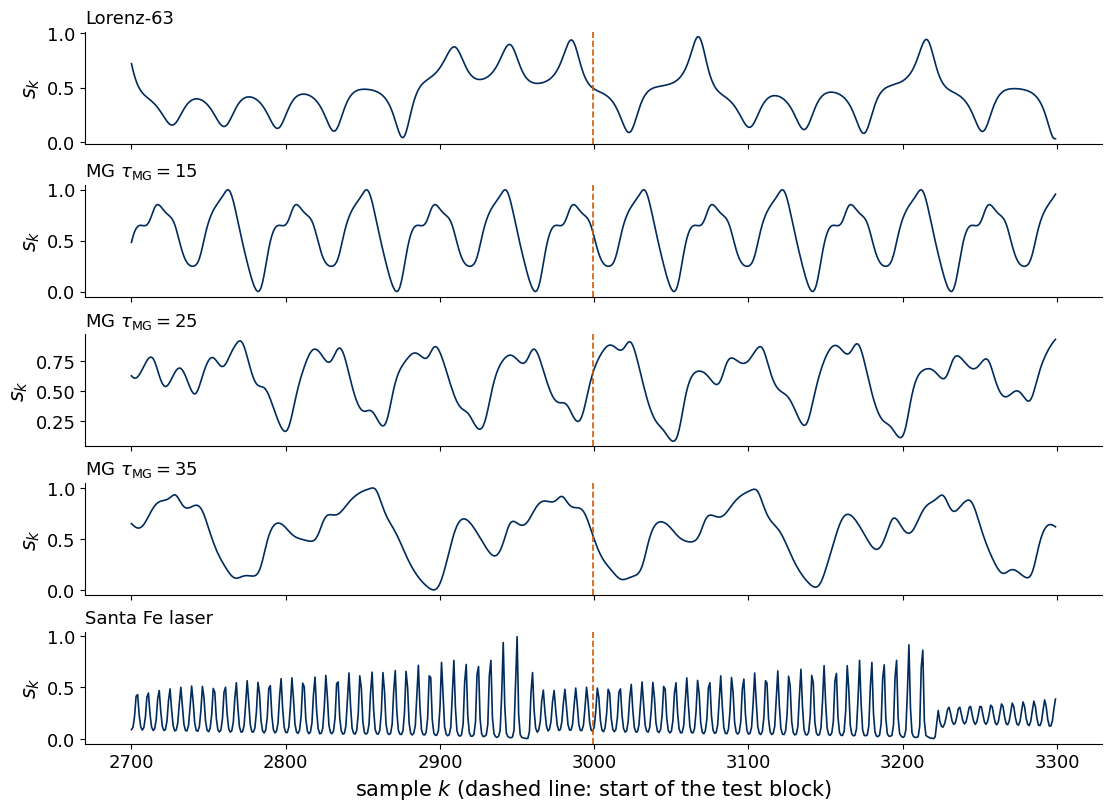

In [3]:
raw = {"Lorenz": np.asarray(lorenz_trajectory(N_SAMPLES)[:, 0]),
       "MG15": mackey_glass(15, N_SAMPLES), "MG25": mackey_glass(25, N_SAMPLES),
       "MG35": mackey_glass(35, N_SAMPLES), "SantaFe": santafe()[:N_SAMPLES]}
SIGNALS = list(raw)
LABEL = {"Lorenz": "Lorenz-63", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$",
         "MG35": r"MG $\tau_{\rm MG}=35$", "SantaFe": "Santa Fe laser"}
sig = {name: rescale01(x) for name, x in raw.items()}     # [0, 1] on the training block (first 3000 samples)
for name in SIGNALS:
    s = sig[name]
    print(f"{name:8s} N = {len(s)}  train range [{s[:N_TRAIN].min():.2f}, {s[:N_TRAIN].max():.2f}]"
          f"  test range [{s[N_TRAIN:].min():.3f}, {s[N_TRAIN:].max():.3f}]")

fig, axs = plt.subplots(5, 1, figsize=(11, 8), sharex=True, layout="constrained")
for ax, name in zip(axs, SIGNALS):
    ax.plot(np.arange(2700, 3300), sig[name][2700:3300], color=UJNavy, lw=1.2)
    ax.axvline(N_TRAIN - 0.5, color=DSOrange, ls="--", lw=1.2)
    ax.set_ylabel(r"$s_k$"); ax.set_title(LABEL[name], loc="left", fontsize=13)
axs[-1].set_xlabel("sample $k$ (dashed line: start of the test block)")
plt.show()

Every signal has $N=4000$ samples, split in time order. The first 3000 form the training block, and its last 500 samples are used for validation. The final 1000 samples are the test block. Each signal is rescaled with the minimum and maximum of the first 3000 values, which include the validation block. The test block is untouched by the scaling, so the test values may exceed $[0,1]$. All benchmark notebooks use this scaling.

A forecast is made at an origin $k$ from the past $s_k,s_{k-1},\dots$ and returns all leads $\tau=1,\dots,50$ at once. The ridge and neural models use direct forecasting, one output per lead. The MA comparison introduced later instead forecasts recursively with future innovations set to zero. The window-based models read at most the last $L=64$ values, and NVAR may select fewer. The ESN carries a continuously driven reservoir state, and MA uses filtered innovations. The common 64-value window and 50 targets are
$$\mathbf v_k=(s_{k-L+1},\dots,s_{k-1},s_k)\in\mathbb R^{L},\qquad \mathbf y_k=(s_{k+1},\dots,s_{k+50})\in\mathbb R^{50}.$$
The origins are chosen so that no target crosses a block boundary. Fitting uses the origins $k=63,\dots,2449$ (targets inside the first 2500 samples), validation the origins $k=2499,\dots,2949$ (targets inside the validation block), and testing the origins $k=2999,\dots,3949$ (targets inside the test block). A window may reach back into an earlier block, since the inputs are past values that are known at the time of the forecast.

In [4]:
L_WIN = 64                                                        # window length L
K_FIT = np.arange(L_WIN - 1, N_TRAIN - N_VAL - TAU_MAX)           # origins 63..2449
K_VAL = np.arange(N_TRAIN - N_VAL - 1, N_TRAIN - TAU_MAX)         # origins 2499..2949
K_TEST = np.arange(N_TRAIN - 1, N_SAMPLES - TAU_MAX)              # origins 2999..3949
TAUS = np.arange(1, TAU_MAX + 1)

def windows(s, ks, L=L_WIN):
    # inputs U[i] = (s_{k-L+1}, ..., s_k) and targets Y[i] = (s_{k+1}, ..., s_{k+50}) for k = ks[i]
    U = s[ks[:, None] + np.arange(-L + 1, 1)[None, :]]
    Y = s[ks[:, None] + TAUS[None, :]]
    return U, Y

U_tmp, Y_tmp = windows(sig["SantaFe"], K_TEST)
assert U_tmp.shape == (len(K_TEST), L_WIN) and Y_tmp.shape == (len(K_TEST), TAU_MAX)
assert U_tmp[0, -1] == sig["SantaFe"][K_TEST[0]] and Y_tmp[0, 0] == sig["SantaFe"][K_TEST[0] + 1]
assert (K_FIT + TAU_MAX).max() < N_TRAIN - N_VAL and (K_VAL + TAU_MAX).max() < N_TRAIN
assert K_TEST[0] + 1 == N_TRAIN and (K_TEST + TAU_MAX).max() == N_SAMPLES - 1
print(f"origins: fit {len(K_FIT)} ({K_FIT[0]}..{K_FIT[-1]}), validation {len(K_VAL)} ({K_VAL[0]}..{K_VAL[-1]}),"
      f" test {len(K_TEST)} ({K_TEST[0]}..{K_TEST[-1]})")
nums["protocol"] = dict(L=L_WIN, n_fit=len(K_FIT), n_val=len(K_VAL), n_test=len(K_TEST), tau_max=TAU_MAX)

origins: fit 2387 (63..2449), validation 451 (2499..2949), test 951 (2999..3949)


### Scores

The scores are those of the notebook on linear models. For each lead $\tau$ we compare the predictions $\hat s_{k+\tau}$ with the true values $s_{k+\tau}$ over the $n$ test origins. The normalised mean-square error $\mathrm{NMSE}(\tau)=\langle(\hat s_{k+\tau}-s_{k+\tau})^2\rangle/\mathrm{Var}(s_{k+\tau})$ measures the error in units of the signal variance, and the Pearson coefficient $r(\tau)$ measures how well the shape of the prediction follows the truth. The forecast capacity $C(\tau)=r(\tau)^2$ lies in $[0,1]$. Its sum over the 50 leads, the total capacity $C_{\rm tot}=\sum_{\tau=1}^{50}C(\tau)\le 50$, summarises a whole curve, and the skill horizon $\tau_{1/2}$ is the first lead with $C(\tau)<0.5$. A capacity close to 1 with a large NMSE means that the shape is right and the scale is wrong, so both are reported.

In [5]:
@jax.jit
def nmse_and_r(pred, true):
    # pred, true: (n, TAU_MAX); averages over the n origins, one value per lead
    err = jnp.mean((pred - true) ** 2, axis=0) / jnp.var(true, axis=0)
    pc, tc = pred - pred.mean(0), true - true.mean(0)
    den = jnp.sqrt(jnp.sum(pc ** 2, 0) * jnp.sum(tc ** 2, 0))
    variable = (jnp.ptp(pred, axis=0) > 0) & (jnp.ptp(true, axis=0) > 0)
    r = jnp.where(variable & (den > 0), jnp.sum(pc * tc, 0) / jnp.where(den > 0, den, 1.0), 0.0)
    return err, r

def score(pred, true):
    # dictionary with NMSE(tau), r(tau), C(tau) = r^2, C_tot and the skill horizon tau_1/2
    e, r = (np.asarray(a) for a in nmse_and_r(jnp.asarray(pred, jnp.float64), jnp.asarray(true, jnp.float64)))
    C = r ** 2
    below = np.nonzero(C < 0.5)[0]
    return dict(nmse=e, r=r, C=C, Ctot=float(C.sum()), tau_half=int(below[0] + 1) if len(below) else None)

# check the JAX scores against numpy on random data
rng = np.random.default_rng(0)
a, b = rng.normal(size=(500, TAU_MAX)), rng.normal(size=(500, TAU_MAX))
sc = score(a + 0.5 * b, b)
r_np = np.array([np.corrcoef(a[:, j] + 0.5 * b[:, j], b[:, j])[0, 1] for j in range(TAU_MAX)])
e_np = np.array([np.mean((a[:, j] - 0.5 * b[:, j]) ** 2) / np.var(b[:, j]) for j in range(TAU_MAX)])
print("max |r_jax - r_numpy| =", np.abs(sc["r"] - r_np).max(), "| max |NMSE_jax - NMSE_numpy| =", np.abs(sc["nmse"] - e_np).max())

max |r_jax - r_numpy| = 5.551115123125783e-16 | max |NMSE_jax - NMSE_numpy| = 6.661338147750939e-16


<hr/>
## 2. Persistence, AR and NVAR baselines

Persistence repeats the last value, $\hat s_{k+\tau}=s_k$. It needs no fitting and gives the lowest level that any model must beat. The direct AR model of order $p$ and the NVAR model are ridge regressions on features of the delay vector $\mathbf d_k=(s_k,s_{k-1},\dots,s_{k-p+1})$,
$$\hat{\mathbf y}_k=W^\top\boldsymbol\phi(\mathbf d_k)+\mathbf b,\qquad \boldsymbol\phi_{\rm AR}=\mathbf d_k,\qquad \boldsymbol\phi_{\rm NVAR}=\big(\mathbf d_k,\ \{s_{k-i}s_{k-j}\}_{0\le i\le j<p}\big),$$
where $W$ has one column per lead and NVAR has $p+p(p+1)/2$ features [Gauthier *et al.*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)]. Ridge regression minimises $\sum_k\|\hat{\mathbf y}_k-\mathbf y_k\|^2+\beta\|W\|^2$. With centred features $\Phi_c$ and centred targets $Y_c$ the solution is
$$W=(\Phi_c^\top\Phi_c+\beta I)^{-1}\Phi_c^\top Y_c,\qquad \mathbf b=\bar{\mathbf y}-W^\top\bar{\boldsymbol\phi},$$
so the intercept $\mathbf b$ is not penalised. The order $p$ and the ridge strength $\beta$ are chosen by the largest $C_{\rm tot}$ on the validation origins. All linear models are treated in detail in the notebook on linear models and NVAR. In the present comparison they are reference points computed with the same origins as the networks.

In [6]:
def ridge_fit(F, Y, beta):
    # centred ridge regression, F: (n, d) features, Y: (n, m) targets -> W (d, m), b (m,)
    fm, ym = F.mean(0), Y.mean(0)
    Fc, Yc = F - fm, Y - ym
    W = jnp.linalg.solve(Fc.T @ Fc + beta * jnp.eye(F.shape[1]), Fc.T @ Yc)
    return W, ym - fm @ W

def delay_features(s, ks, p):
    # rows (s_k, s_{k-1}, ..., s_{k-p+1})
    return s[ks[:, None] - np.arange(p)[None, :]]

def nvar_features(s, ks, p):
    # delay vector and all quadratic monomials s_{k-i} s_{k-j}, i <= j
    d = delay_features(s, ks, p)
    iu, ju = np.triu_indices(p)
    return np.concatenate([d, d[:, iu] * d[:, ju]], axis=1)

GRID_BETA = (1e-8, 1e-6, 1e-4, 1e-2, 1.0)
GRID_P = {"AR": (4, 8, 16, 24, 32, 48, 64), "NVAR": (2, 4, 8, 12, 16, 24, 32)}
FEATS = {"AR": delay_features, "NVAR": nvar_features}

def ridge_model(s, kind):
    # choose (p, beta) by validation C_tot, return the test predictions and the chosen setting
    _, Yf = windows(s, K_FIT); _, Yv = windows(s, K_VAL); _, Yt = windows(s, K_TEST)
    best = (-1.0, None, None)
    for p in GRID_P[kind]:
        Ff, Fv = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_VAL, p)
        for beta in GRID_BETA:
            W, b = ridge_fit(Ff, Yf, beta)
            ctot = score(Fv @ W + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, p, beta)
    _, p, beta = best
    Ff, Ft = FEATS[kind](s, K_FIT, p), FEATS[kind](s, K_TEST, p)
    t0 = time.perf_counter()
    W, b = ridge_fit(Ff, Yf, beta); W.block_until_ready()
    t_fit = time.perf_counter() - t0
    return dict(pred=np.asarray(Ft @ W + b), p=p, beta=beta, W=np.asarray(W), b=np.asarray(b),
                n_feat=Ff.shape[1], t_fit=t_fit, **score(Ft @ W + b, Yt))

res = {name: {} for name in SIGNALS}       # res[signal][model] = scores and predictions on the test origins
for name in SIGNALS:
    s = sig[name]
    U, Yt = windows(s, K_TEST)
    res[name]["persistence"] = dict(pred=np.repeat(U[:, -1:], TAU_MAX, 1), **score(np.repeat(U[:, -1:], TAU_MAX, 1), Yt))
    for kind in ("AR", "NVAR"):
        res[name][kind] = ridge_model(s, kind)
    print(f"{name:8s} C_tot: persistence {res[name]['persistence']['Ctot']:5.1f} | "
          + " | ".join(f"{k} {res[name][k]['Ctot']:5.1f} (p={res[name][k]['p']}, beta={res[name][k]['beta']:.0e})"
                       for k in ("AR", "NVAR")))

Lorenz   C_tot: persistence   8.4 | AR  15.4 (p=16, beta=1e-08) | NVAR  15.4 (p=16, beta=1e-08)
MG15     C_tot: persistence  19.5 | AR  49.8 (p=64, beta=1e-08) | NVAR  50.0 (p=32, beta=1e-08)
MG25     C_tot: persistence  13.3 | AR  33.1 (p=64, beta=1e-08) | NVAR  45.5 (p=32, beta=1e-08)
MG35     C_tot: persistence  11.8 | AR  38.0 (p=64, beta=1e-08) | NVAR  48.6 (p=32, beta=1e-08)
SantaFe  C_tot: persistence   5.5 | AR  16.5 (p=64, beta=1e+00) | NVAR  34.7 (p=32, beta=1e-02)


The same ridge regression with scikit-learn gives the same predictions, since `Ridge` with `fit_intercept=True` also centres the data and leaves the intercept unpenalised.

In [7]:
s = sig["SantaFe"]; p, beta = res["SantaFe"]["AR"]["p"], res["SantaFe"]["AR"]["beta"]
_, Yf = windows(s, K_FIT)
sk = SkRidge(alpha=beta, fit_intercept=True).fit(delay_features(s, K_FIT, p), Yf)
diff = np.abs(sk.predict(delay_features(s, K_TEST, p)) - res["SantaFe"]["AR"]["pred"]).max()
print(f"Santa Fe AR(p={p}): max |prediction JAX - prediction scikit-learn| = {diff:.2e}")

Santa Fe AR(p=64): max |prediction JAX - prediction scikit-learn| = 1.39e-15


<hr/>
## 3. Multilayer perceptron on the delay window

The Santa Fe laser shows the limits of a linear model. The intensity grows over many pulsations and then collapses, so the same recent values can be followed either by a larger pulse or by a collapse. The map from the past window to the future folds the reconstructed attractor, and a weighted sum of past values cannot represent a fold. Five steps ahead the AR forecast underestimates the large pulses and spreads the small ones.

A one-hidden-layer perceptron on the window $\mathbf v_k$ computes
$$\hat{\mathbf y}_k=W_2\tanh(W_1\mathbf v_k+\mathbf b_1)+\mathbf b_2,\qquad W_1\in\mathbb R^{n_{\rm hid}\times L},\ W_2\in\mathbb R^{50\times n_{\rm hid}}.$$
The universal approximation theorem guarantees that such a network with enough hidden units approximates any continuous function on a compact set to any accuracy [Cybenko, Math. Control Signals Syst. **2**, 303 (1989), [doi:10.1007/BF02551274](https://doi.org/10.1007/BF02551274); Hornik, Neural Netw. **4**, 251 (1991), [doi:10.1016/0893-6080(91)90009-T](https://doi.org/10.1016/0893-6080(91)90009-T)]. The theorem says nothing about how many units are needed or whether gradient descent finds the weights. The network is a nonlinear representation of the past, $\tanh(W_1\mathbf v_k+\mathbf b_1)$, followed by a linear map to the future. In NVAR this representation is a fixed list of monomials, and in the MLP it is learned. We use $n_{\rm hid}=64$ hidden units.

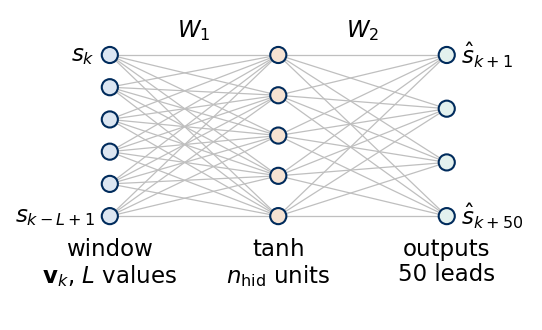

In [8]:
def draw_layers(ax, sizes, labels, xs, ys_span=2.2, node_r=0.11, colors=None, edge_color="0.75"):
    # nodes-and-edges drawing of a fully connected network; sizes[i] nodes in column xs[i], all-to-all edges
    cols = []
    for n, x in zip(sizes, xs):
        ys = np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0])
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):            # edges first, nodes on top
        for (x0, y0) in a:
            for (x1, y1) in b:
                ax.plot([x0, x1], [y0, y1], color=edge_color, lw=0.6, zorder=1)
    for i, col in enumerate(cols):
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=1.0, zorder=3))
    for i, lab in enumerate(labels):                  # one label per column, placed below it
        ax.text(xs[i], -ys_span / 2 - 0.3, lab, ha="center", va="top", linespacing=1.1)
    return cols

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.6))
    cols = draw_layers(ax, [6, 5, 4], ["window\n" + r"$\mathbf{v}_k$, $L$ values", r"$\tanh$" + "\n" + r"$n_{\rm hid}$ units",
                                       "outputs\n50 leads"], xs=[0, 2.3, 4.6], colors=["#DCE6F2", "#F6E3D3", "#E3F1EE"])
    for (x, y), t in zip([cols[0][0], cols[0][-1]], [r"$s_k$", r"$s_{k-L+1}$"]):
        ax.text(x - 0.2, y, t, ha="right", va="center")
    for (x, y), t in zip([cols[2][0], cols[2][-1]], [r"$\hat s_{k+1}$", r"$\hat s_{k+50}$"]):
        ax.text(x + 0.2, y, t, ha="left", va="center")
    ax.text(1.15, 1.35, "$W_1$", ha="center"); ax.text(3.45, 1.35, "$W_2$", ha="center")
    ax.set_xlim(-1.2, 5.7); ax.set_ylim(-2.45, 1.65); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_mlp_window"); plt.show()

### Training loop

All networks are trained by one function. The training set consists of the windows $(\mathbf v_k,\mathbf y_k)$ for the fitting origins, an array of shape $(n_{\rm fit},L,1)$ of inputs and $(n_{\rm fit},50)$ of targets. Neighbouring windows overlap in $L-1$ values, so they are far from independent samples, and we shuffle them at every epoch and cut them into minibatches of 128 windows. The loss is the mean-square error over the minibatch and all 50 leads,
$$\mathcal L=\frac{1}{50\,B}\sum_{k\in\text{batch}}\|\hat{\mathbf y}_k-\mathbf y_k\|^2 .$$
The Adam optimiser with learning rate $5\times10^{-3}$ updates the weights. Before every update the gradient is rescaled when its Euclidean norm over all parameters exceeds 1. This gradient clipping [Pascanu *et al.*, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)] protects against the rare very large gradients of recurrent networks discussed in Section 5. After every epoch we compute the loss on the validation windows. We keep the parameters with the lowest validation loss and stop when it has not improved for 20 epochs, at most after 250 epochs. This early stopping is the only protection against overfitting that we use, and the test block is never looked at during training.

The function `nnx.split` separates a model into its structure (`graphdef`) and its parameters, which makes the loss a pure function of the parameters. `jax.value_and_grad` returns loss and gradient, `optax.chain(clip_by_global_norm, adam)` turns the gradient into an update, and one `jax.lax.scan` over the minibatches forms an epoch that `jax.jit` compiles once.

In [9]:
BATCH, LR, CLIP, MAX_EPOCHS, PATIENCE = 128, 5e-3, 1.0, 250, 20

def n_params(model):
    return int(sum(x.size for x in jax.tree.leaves(nnx.state(model, nnx.Param))))

def fit_network(model, data, seed=0, epochs=MAX_EPOCHS, patience=PATIENCE, verbose=True):
    # data = (U_fit, Y_fit, U_val, Y_val), inputs of shape (n, L, 1), float32
    Uf, Yf, Uv, Yv = data
    graphdef, params, rest = nnx.split(model, nnx.Param, ...)
    tx = optax.chain(optax.clip_by_global_norm(CLIP), optax.adam(LR))
    opt_state = tx.init(params)
    n = Uf.shape[0]; n_batches = n // BATCH

    def loss_fn(p, U, Y):
        return jnp.mean((nnx.merge(graphdef, p, rest)(U) - Y) ** 2)

    @jax.jit
    def epoch(p, opt_state, key):
        idx = jax.random.permutation(key, n)[: n_batches * BATCH].reshape(n_batches, BATCH)
        def step(carry, ib):
            p, opt_state = carry
            loss, g = jax.value_and_grad(loss_fn)(p, Uf[ib], Yf[ib])
            gnorm = optax.global_norm(g)                  # norm before clipping
            upd, opt_state = tx.update(g, opt_state, p)
            return (optax.apply_updates(p, upd), opt_state), (loss, gnorm)
        (p, opt_state), (losses, gnorms) = jax.lax.scan(step, (p, opt_state), idx)
        return p, opt_state, losses.mean(), gnorms, loss_fn(p, Uv, Yv)

    key = jax.random.key(seed)
    hist = dict(train=[], val=[], gnorm=[], clipped=[])
    best_val, best_params, best_ep, t0 = np.inf, params, 0, time.time()
    for ep in range(epochs):
        key, sub = jax.random.split(key)
        params, opt_state, l_tr, gn, l_va = epoch(params, opt_state, sub)
        gn = np.asarray(gn)
        hist["train"].append(float(l_tr)); hist["val"].append(float(l_va))
        hist["gnorm"].append(float(np.median(gn))); hist["clipped"].append(float(np.mean(gn > CLIP)))
        if float(l_va) < best_val:
            best_val, best_params, best_ep = float(l_va), params, ep
        elif ep - best_ep >= patience:
            break
    hist = {k: np.array(v) for k, v in hist.items()}
    hist.update(best_epoch=best_ep + 1, epochs_run=ep + 1, time=time.time() - t0, best_val=best_val)
    if verbose:
        print(f"    {ep + 1:3d} epochs, best validation loss {best_val:.2e} at epoch {best_ep + 1},"
              f" {hist['time']:.1f} s")
    return nnx.merge(graphdef, best_params, rest), hist

def net_data(s, L=L_WIN):
    # float32 windows (n, L, 1) and targets (n, 50) for fitting, validation and test origins
    out = []
    for ks in (K_FIT, K_VAL, K_TEST):
        U, Y = windows(s, ks, L)
        out += [jnp.asarray(U[..., None], jnp.float32), jnp.asarray(Y, jnp.float32)]
    return out

def predict(model, U):
    return np.asarray(model(U), np.float64)

The MLP module flattens the window and applies the two layers. `nnx.Linear` initialises each weight matrix with the LeCun normal distribution, variance $1/n_{\rm in}$, which keeps the pre-activations of order one for inputs of order one, and the biases with zeros.

In [10]:
N_MLP = 64

class MLP(nnx.Module):
    def __init__(self, L, n_hid, n_out, *, rngs):
        self.l1 = nnx.Linear(L, n_hid, rngs=rngs)        # W_1, b_1
        self.l2 = nnx.Linear(n_hid, n_out, rngs=rngs)    # W_2, b_2
    def __call__(self, U):
        # U: (batch, L, 1) -> (batch, 50)
        return self.l2(jnp.tanh(self.l1(U[..., 0])))

data_sf = net_data(sig["SantaFe"])
mlp_sf, hist_mlp_sf = fit_network(MLP(L_WIN, N_MLP, TAU_MAX, rngs=nnx.Rngs(0)), data_sf[:4], seed=0)
sc_mlp_sf = score(predict(mlp_sf, data_sf[4]), np.asarray(data_sf[5]))
print(f"MLP ({n_params(mlp_sf)} parameters) on Santa Fe: C_tot = {sc_mlp_sf['Ctot']:.1f},"
      f" C(5) = {sc_mlp_sf['C'][4]:.3f} | AR: C(5) = {res['SantaFe']['AR']['C'][4]:.3f}")

    250 epochs, best validation loss 1.12e-02 at epoch 244, 2.6 s
MLP (7410 parameters) on Santa Fe: C_tot = 35.3, C(5) = 0.893 | AR: C(5) = 0.767


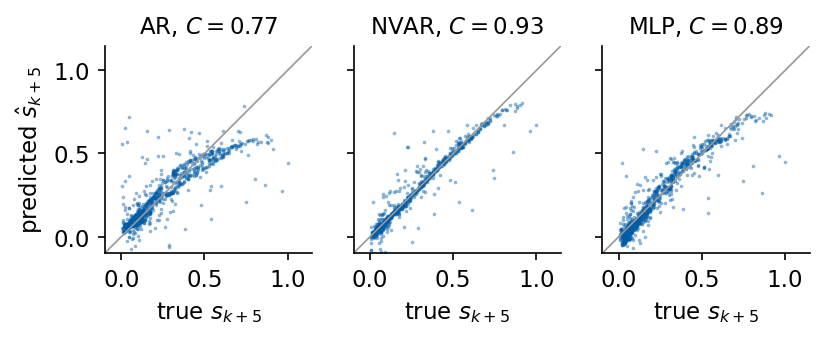

In [11]:
def scatter_panel(ax, true, pred, title, lim=(-0.1, 1.15)):
    ax.plot(lim, lim, color="0.6", lw=0.8)
    ax.scatter(true, pred, s=3, color=UJBlue, alpha=0.45, lw=0)
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_aspect("equal")
    ax.set_title(title, fontsize=11)

Yt_sf = np.asarray(data_sf[5], np.float64)
tau_show = 5
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.15), sharey=True, layout="constrained")
    for ax, (lab, P) in zip(axs, [("AR", res["SantaFe"]["AR"]["pred"]), ("NVAR", res["SantaFe"]["NVAR"]["pred"]),
                                  ("MLP", predict(mlp_sf, data_sf[4]))]):
        C = np.corrcoef(P[:, tau_show - 1], Yt_sf[:, tau_show - 1])[0, 1] ** 2
        scatter_panel(ax, Yt_sf[:, tau_show - 1], P[:, tau_show - 1], f"{lab}, $C={C:.2f}$")
        ax.set_xlabel(r"true $s_{k+5}$")
    axs[0].set_ylabel(r"predicted $\hat s_{k+5}$")
    save(fig, "fig_santafe_linear_vs_mlp"); plt.show()
nums["santafe_C5"] = {m: float(res["SantaFe"][m]["C"][4]) for m in ("AR", "NVAR")}
nums["santafe_C5"]["MLP"] = float(sc_mlp_sf["C"][4])

Five steps ahead the AR forecast reaches $C=0.77$. It compresses the large pulses towards the mean, and points with the same true value are spread over a wide band of predictions. The quadratic features of NVAR raise the capacity to $0.93$ and the MLP with learned features to $0.89$. NVAR follows the diagonal also for the large pulses, and the MLP up to true values of about 0.75, above which its predictions level off. The MLP is trained on the same windows as NVAR and only replaces the fixed list of monomials by 64 learned tanh features.

<hr/>
## 4. Reservoir computing and the echo state network

The MLP sees a fixed window of $L$ values, as do AR and NVAR. A system with an internal state can carry the history in that state instead. Reservoir computing takes a fixed nonlinear dynamical system, the reservoir, drives it with the input and trains only a linear readout of its state. Any physical system with three properties can act as a reservoir. It must respond nonlinearly to the input, it must have fading memory, so that the state depends on the recent input and forgets the distant past, and it must offer many variables that can be read out. Nakajima *et al.* used a soft silicone arm, about 45 cm long and moving underwater, whose base angle was the input and whose 10 bend sensors along the arm were the state [Nakajima, Hauser, Li and Pfeifer, Sci. Rep. **5**, 10487 (2015), [doi:10.1038/srep10487](https://doi.org/10.1038/srep10487)]. The water drag supplies the nonlinearity and the damped relaxation of the arm the fading memory, and a weighted sum of the sensor signals was trained for several tasks at once.

The echo state network is the computer version of this idea [Jaeger, GMD Report 148 (2001); Lukoševičius and Jaeger, Comput. Sci. Rev. **3**, 127 (2009), [doi:10.1016/j.cosrev.2009.03.005](https://doi.org/10.1016/j.cosrev.2009.03.005)]. Its state $\mathbf x_k\in\mathbb R^{N}$ follows the leaky update
$$\mathbf x_k=(1-\alpha)\,\mathbf x_{k-1}+\alpha\tanh\!\big(W\mathbf x_{k-1}+\mathbf w_{\rm in}s_k\big),$$
with a sparse random matrix $W$ (10% nonzero Gaussian entries) rescaled to the spectral radius $\rho=\max_i|\lambda_i(W)|$, a random input vector $\mathbf w_{\rm in}$ with entries uniform in $[-\sigma_{\rm in},\sigma_{\rm in}]$, and the leak rate $\alpha\in(0,1]$. Neither $W$ nor $\mathbf w_{\rm in}$ is trained. The readout $\hat{\mathbf y}_k=W_{\rm out}^\top\mathbf x_k+\mathbf b$ is a ridge regression, the same as for AR and NVAR. The ESN is a recurrent network whose recurrence is random and fixed, and the training problem is convex.

In [12]:
def esn_base(N, seed, density=0.1):
    # random sparse W rescaled to spectral radius 1 and input vector uniform in [-1, 1]; scaled later by rho, sigma_in
    rng = np.random.default_rng(seed)
    W = rng.normal(size=(N, N)) * (rng.random((N, N)) < density)
    W /= np.max(np.abs(np.linalg.eigvals(W)))
    return W, rng.uniform(-1.0, 1.0, size=N)

@jax.jit
def esn_states(W, w_in, u, alpha, x0):
    # x_k = (1 - alpha) x_{k-1} + alpha tanh(W x_{k-1} + w_in u_k), returns all states (T, N)
    def step(x, uk):
        x = (1.0 - alpha) * x + alpha * jnp.tanh(W @ x + w_in * uk)
        return x, x
    _, X = jax.lax.scan(step, x0, u)
    return X

# the same reservoir in ReservoirPy, with our W and w_in passed in (bias 0, lr = leak rate alpha)
W0, w0 = esn_base(100, seed=0)
rho, sigma_in, alpha = 0.9, 0.5, 0.3
X_jax = np.asarray(esn_states(rho * W0, sigma_in * w0, sig["SantaFe"], alpha, jnp.zeros(100)))
rpy_res = Reservoir(W=rho * W0, Win=(sigma_in * w0)[:, None], bias=0.0, lr=alpha, input_dim=1)
X_rpy = rpy_res.run(sig["SantaFe"][:, None])
print("states", X_jax.shape, "| max |x_JAX - x_ReservoirPy| =", np.abs(X_jax - X_rpy).max())

states (4000, 100) | max |x_JAX - x_ReservoirPy| = 3.3306690738754696e-16


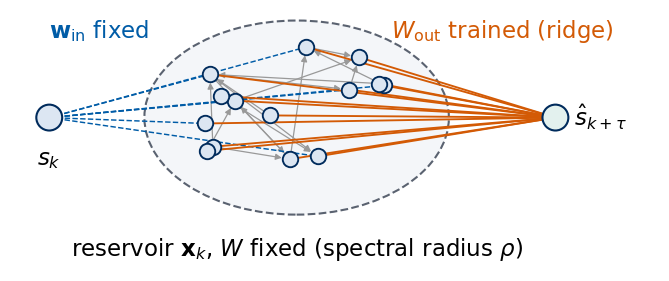

In [13]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3))
    rng = np.random.default_rng(3)
    n_res = 14                                           # nodes drawn (the reservoir has N of them)
    ang = rng.uniform(0, 2 * np.pi, n_res); rad = np.sqrt(rng.uniform(0.05, 1, n_res))
    P = np.c_[3.6 + 1.55 * rad * np.cos(ang), 1.2 + 0.95 * rad * np.sin(ang)]
    ax.add_patch(Ellipse((3.6, 1.2), 4.0, 2.55, fc="#F4F6F9", ec=UJGray, ls="--", lw=1.0, zorder=0))
    for i in range(n_res):                               # fixed random recurrent couplings W (sparse)
        for j in range(n_res):
            if i != j and rng.random() < 0.13:
                ax.annotate("", xy=P[j], xytext=P[i], arrowprops=dict(arrowstyle="-|>", color="0.6", lw=0.6,
                            shrinkA=4, shrinkB=4, mutation_scale=6), zorder=1)
    s_xy, y_xy = np.array([0.35, 1.2]), np.array([7.0, 1.2])
    for i in rng.choice(n_res, 7, replace=False):        # fixed input couplings w_in
        ax.plot(*np.c_[s_xy, P[i]], color=UJBlue, lw=0.7, ls="--", zorder=1)
    for i in range(n_res):                               # trained readout W_out
        ax.plot(*np.c_[P[i], y_xy], color=DSOrange, lw=0.9, zorder=1)
    ax.scatter(*P.T, s=55, color="#DCE6F2", edgecolor=UJNavy, lw=0.9, zorder=3)
    ax.add_patch(Circle(s_xy, 0.17, fc="#DCE6F2", ec=UJNavy, zorder=3))
    ax.add_patch(Circle(y_xy, 0.17, fc="#E3F1EE", ec=UJNavy, zorder=3))
    ax.text(s_xy[0], 0.8, r"$s_k$", ha="center", va="top")
    ax.text(y_xy[0] + 0.25, 1.2, r"$\hat s_{k+\tau}$", ha="left", va="center")
    ax.text(1.0, 2.25, r"$\mathbf{w}_{\rm in}$ fixed", color=UJBlue, ha="center")
    ax.text(3.6, -0.35, r"reservoir $\mathbf{x}_k$, $W$ fixed (spectral radius $\rho$)", ha="center", va="top")
    ax.text(6.3, 2.25, r"$W_{\rm out}$ trained (ridge)", color=DSOrange, ha="center")
    ax.set_xlim(-0.1, 8.3); ax.set_ylim(-0.75, 2.55); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_esn_diagram"); plt.show()

### Echo state property

A single linear readout can only work if the state is a function of the input history alone and does not depend on the arbitrary initial state $\mathbf x_0$. This is the echo state property. We test it directly with one reservoir of $N=100$ units, which is started from two random initial states and driven by the same input, the rescaled Santa Fe signal, with $\alpha=1$ and $\sigma_{\rm in}=0.5$. We plot the distance $\|\mathbf x_k-\mathbf x'_k\|$ between the two copies for several spectral radii, and once for $\rho=1.2$ with the input switched off. The update is a contraction, and the property is guaranteed, when the largest singular value of $W$ is below 1 [Jaeger, GMD Report 148 (2001)]. The spectral radius is the usual practical control parameter.

largest singular value of W rescaled to rho = 1: 2.21
$\rho=0.8$             |x_k - x'_k| at k = 300: 2.56e-16
$\rho=1.2$             |x_k - x'_k| at k = 300: 6.25e+00
$\rho=2.0$             |x_k - x'_k| at k = 300: 9.50e+00
$\rho=1.2$, no input   |x_k - x'_k| at k = 300: 7.49e+00


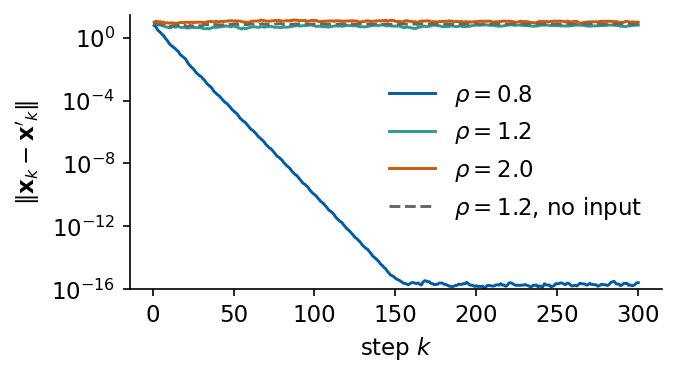

In [14]:
def esp_distance(rho, sigma_in, u, seed=1, N=100):
    # distance between two copies of one reservoir started from different random states, same input u
    W, w = esn_base(N, seed=0)
    rng = np.random.default_rng(seed)
    xa, xb = rng.uniform(-1, 1, N), rng.uniform(-1, 1, N)
    Xa = esn_states(rho * W, sigma_in * w, u, 1.0, xa)
    Xb = esn_states(rho * W, sigma_in * w, u, 1.0, xb)
    return np.linalg.norm(np.asarray(Xa - Xb), axis=1)

u_esp = sig["SantaFe"][:300]
cases = [(0.8, 0.5, u_esp, r"$\rho=0.8$"), (1.2, 0.5, u_esp, r"$\rho=1.2$"),
         (2.0, 0.5, u_esp, r"$\rho=2.0$"), (1.2, 0.5, 0 * u_esp, r"$\rho=1.2$, no input")]
sv_max = np.linalg.norm(esn_base(100, seed=0)[0], 2)
print(f"largest singular value of W rescaled to rho = 1: {sv_max:.2f}")
nums["esp"] = {}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.4), layout="constrained")
    for (rho_, si, u, lab), c in zip(cases, [UJBlue, "#2A9D8F", DSOrange, "0.4"]):
        d = esp_distance(rho_, si, u)
        ax.semilogy(np.arange(1, len(d) + 1), np.maximum(d, 1e-16), color=c, ls="--" if "no input" in lab else "-", label=lab)
        nums["esp"][lab.replace("$", "").replace("\\", "")] = dict(d_end=float(d[-1]), d_mean_last100=float(d[-100:].mean()))
        print(f"{lab:22s} |x_k - x'_k| at k = 300: {d[-1]:.2e}")
    ax.set_xlabel("step $k$"); ax.set_ylabel(r"$\|\mathbf{x}_k-\mathbf{x}'_k\|$")
    ax.set_ylim(1e-16, 30); ax.legend(loc="center right")
    save(fig, "fig_esp_convergence"); plt.show()

With $\rho=0.8$ the two copies approach each other exponentially and reach the round-off level of $10^{-16}$ after about 150 steps, so the state forgets where it started. With $\rho=1.2$ and $\rho=2.0$ the distance stays of order one over all 300 steps, with and without input. The largest singular value of this $W$ at $\rho=1$ is 2.21, so the sufficient contraction condition $\sigma_{\max}(\rho W)<1$ holds only for $\rho<0.45$. The convergence at $\rho=0.8$ is therefore a property of this reservoir and this input that the bound does not guarantee. For this reservoir the input does not restore convergence above $\rho=1$. The rule $\rho<1$ is a working rule, and the direct test with two initial states is the check.

### Linear memory capacity

How much of its input history a reservoir stores is measured with a task whose input cannot be predicted from itself. The input $u_k$ is drawn independently and uniformly from $[-1,1]$, and for every delay $d$ a separate linear readout of $\mathbf x_k$ is trained to return $u_{k-d}$. Its score on test data is $C(d)=r^2(\hat u_{k-d},u_{k-d})$, and the linear memory capacity is
$$\mathrm{MC}=\sum_{d\ge1}C(d)\le N,$$
bounded by the number of linearly independent state variables [Jaeger, GMD Report 148 (2001); Dambre *et al.*, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)]. We use $N=50$, $\alpha=1$, a small input scaling $\sigma_{\rm in}=0.1$, so that the units work close to their linear range, delays $d=1,\dots,100$, 5000 training steps and 2000 test steps after 200 discarded steps.

rho = 0.50: MC =  12.5 (bound N = 50), C(d) > 0.5 up to d = 13
rho = 0.80: MC =  17.8 (bound N = 50), C(d) > 0.5 up to d = 18
rho = 0.95: MC =  20.0 (bound N = 50), C(d) > 0.5 up to d = 19
rho = 1.10: MC =  16.9 (bound N = 50), C(d) > 0.5 up to d = 15


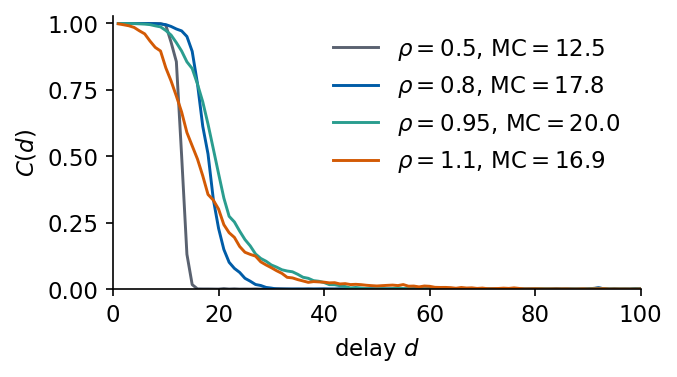

In [15]:
def memory_capacity(rho, N=50, sigma_in=0.1, d_max=100, n_wash=200, n_train=5000, n_test=2000, seed=0, beta=1e-10):
    W, w = esn_base(N, seed=seed)
    u = np.random.default_rng(100 + seed).uniform(-1, 1, n_wash + n_train + n_test)
    X = np.asarray(esn_states(rho * W, sigma_in * w, u, 1.0, jnp.zeros(N)))
    k_tr = np.arange(n_wash, n_wash + n_train); k_te = np.arange(n_wash + n_train, len(u))
    D = np.arange(1, d_max + 1)
    W_out, b = ridge_fit(X[k_tr], u[k_tr[:, None] - D[None, :]], beta)        # one column per delay d
    pred = np.asarray(X[k_te] @ W_out + b)
    return np.array([np.corrcoef(pred[:, j], u[k_te - d])[0, 1] ** 2 for j, d in enumerate(D)])

nums["memory_capacity"] = {}
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.4), layout="constrained")
    for rho_, c in zip((0.5, 0.8, 0.95, 1.1), (UJGray, UJBlue, "#2A9D8F", DSOrange)):
        Cd = memory_capacity(rho_)
        nums["memory_capacity"][f"rho_{rho_}"] = float(Cd.sum())
        ax.plot(np.arange(1, 101), Cd, color=c, label=rf"$\rho={rho_}$, MC$={Cd.sum():.1f}$")
        print(f"rho = {rho_:4.2f}: MC = {Cd.sum():5.1f} (bound N = 50), C(d) > 0.5 up to d = {np.argmax(Cd < 0.5)}")
    ax.set_xlabel("delay $d$"); ax.set_ylabel("$C(d)$"); ax.set_ylim(0, 1.03); ax.set_xlim(0, 100)
    ax.legend(loc="upper right")
    save(fig, "fig_memory_capacity"); plt.show()

The memory curves stay close to $C(d)=1$ for short delays and fall to zero over a range of delays that moves outwards as $\rho$ grows up to $0.95$. The capacity rises from 12.5 at $\rho=0.5$ to 20.0 at $\rho=0.95$ and drops to 16.9 at $\rho=1.1$, where $C(d)$ falls below 1 already at the shortest delays. A longer memory requires slower relaxation, which a larger spectral radius provides until the reservoir starts to lose the echo state property. All values stay well below the bound $N=50$ for this tanh reservoir with sparse random couplings.

### NARMA benchmark

A useful reservoir needs nonlinearity as well as memory. The nonlinear autoregressive moving-average task of order $n$ (NARMA-$n$) asks for memory and nonlinearity together [Atiya and Parlos, IEEE Trans. Neural Netw. **11**, 697 (2000), [doi:10.1109/72.846741](https://doi.org/10.1109/72.846741)]. An input $u_k$ uniform in $[0,0.5]$ drives the system
$$y_k=0.3\,y_{k-1}+0.05\,y_{k-1}\sum_{i=1}^{n}y_{k-i}+1.5\,u_{k-n}u_{k-1}+0.1 ,$$
and the model, which sees only $u$, must return $y_{k+1}$ at time $k$. The product $u_{k-n}u_{k-1}$ needs a memory of $n$ steps and a multiplication, and the feedback through $y$ adds a dependence on older inputs. Nakajima *et al.* trained the soft arm on NARMA-2 to NARMA-20 and report that a linear fit on the raw input fails from NARMA-5 on. We compare three models trained on the same data. The first is a linear readout of the last 20 inputs, the second a quadratic readout (NVAR) of the last 12 inputs, and the third an ESN with $N=100$ units whose $\rho$, $\sigma_{\rm in}$ and ridge strength are chosen on validation data. The score is the NMSE on 1000 test steps after 2500 fitting and 500 validation steps.

ReservoirPy contains a NARMA generator, `reservoirpy.datasets.narma`. Its loop computes $y_{t+1}=a_1y_t+a_2y_t\sum_{j=t-n}^{t-1}y_j+b\,u_{t-n}u_t+c$, so with $k=t+1$ its sum runs over $y_{k-2},\dots,y_{k-n-1}$ and its product is $u_{k-n-1}u_{k-1}$, shifted by one step from our definition of NARMA-$n$. Our generator takes the first lag of the sum and the lag of the product as arguments, and with the shifted values it reproduces the library series.

In [16]:
@partial(jax.jit, static_argnums=(1, 2, 3))
def narma(u, n, i0=1, m=None):
    # y_k = 0.3 y_{k-1} + 0.05 y_{k-1} sum_{i=i0}^{i0+n-1} y_{k-i} + 1.5 u_{k-m} u_{k-1} + 0.1, y = 0 before k = n+1
    m = n if m is None else m
    def body(k, y):
        window = jax.lax.dynamic_slice(y, (k - i0 - n + 1,), (n,))      # y_{k-i0-n+1}, ..., y_{k-i0}
        return y.at[k].set(0.3 * y[k - 1] + 0.05 * y[k - 1] * window.sum() + 1.5 * u[k - m] * u[k - 1] + 0.1)
    return jax.lax.fori_loop(n + 1, u.shape[0], body, jnp.zeros_like(u))

u_chk = np.random.default_rng(7).uniform(0, 0.5, 1010)
_, y_rpy = rpy_narma(n_timesteps=1000, order=10, a1=0.3, a2=0.05, b=1.5, c=0.1, u=u_chk[:, None])
y_ours = np.asarray(narma(jnp.asarray(u_chk), 10, 2, 11))[10:]
print("NARMA-10, library index convention: max |y_JAX - y_ReservoirPy| =", np.abs(y_ours - y_rpy[:, 0]).max())

N_WASH_N, N_FIT_N, N_VAL_N, N_TEST_N = 200, 2500, 500, 1000
u_n = np.random.default_rng(11).uniform(0, 0.5, N_WASH_N + N_FIT_N + N_VAL_N + N_TEST_N + 1)
k_all = np.arange(N_WASH_N, len(u_n) - 1)                         # forecast times k, target y_{k+1}
k_fit, k_val, k_test = np.split(k_all, [N_FIT_N, N_FIT_N + N_VAL_N])

def nmse(pred, true):
    return float(np.mean((pred - true) ** 2) / np.var(true))

def fit_select(F, y, betas=(1e-8, 1e-6, 1e-4, 1e-2)):
    # ridge on rows k_fit, beta chosen on k_val; returns (validation NMSE, test NMSE)
    best = (np.inf, None)
    for beta in betas:
        W_, b_ = ridge_fit(F[k_fit], y[k_fit + 1, None], beta)
        e = nmse(np.asarray(F[k_val] @ W_ + b_)[:, 0], y[k_val + 1])
        if e < best[0]:
            best = (e, nmse(np.asarray(F[k_test] @ W_ + b_)[:, 0], y[k_test + 1]))
    return best

W_n, w_n = esn_base(100, seed=2)
narma_tab = {}
for n in (2, 5, 10):
    y = np.asarray(narma(jnp.asarray(u_n), n))
    assert np.isfinite(y).all()
    lin = delay_features(u_n, np.arange(len(u_n)).clip(19), 20)        # (u_k, ..., u_{k-19}); rows k < 19 unused
    quad = nvar_features(u_n, np.arange(len(u_n)).clip(11), 12)
    row = {"linear (20 inputs)": fit_select(lin, y)[1], "NVAR (12 inputs)": fit_select(quad, y)[1]}
    best_esn = (np.inf, None, None)
    for rho_ in (0.5, 0.8, 0.95):
        for si in (0.1, 0.5, 1.0):
            X = np.asarray(esn_states(rho_ * W_n, si * w_n, u_n, 1.0, jnp.zeros(100)))
            e_val, e_test = fit_select(X, y)
            if e_val < best_esn[0]:
                best_esn = (e_val, e_test, (rho_, si))
    row["ESN (N = 100)"] = best_esn[1]
    narma_tab[n] = row
    print(f"NARMA-{n:<2d} test NMSE: " + " | ".join(f"{k} {v:.3f}" for k, v in row.items())
          + f"   (ESN rho = {best_esn[2][0]}, sigma_in = {best_esn[2][1]})")
nums["narma_nmse"] = {f"n{n}": v for n, v in narma_tab.items()}

NARMA-10, library index convention: max |y_JAX - y_ReservoirPy| = 1.1102230246251565e-16
NARMA-2  test NMSE: linear (20 inputs) 0.105 | NVAR (12 inputs) 0.000 | ESN (N = 100) 0.000   (ESN rho = 0.5, sigma_in = 1.0)
NARMA-5  test NMSE: linear (20 inputs) 0.129 | NVAR (12 inputs) 0.000 | ESN (N = 100) 0.006   (ESN rho = 0.5, sigma_in = 1.0)
NARMA-10 test NMSE: linear (20 inputs) 0.148 | NVAR (12 inputs) 0.100 | ESN (N = 100) 0.094   (ESN rho = 0.95, sigma_in = 0.5)


The linear readout of the last 20 inputs leaves an NMSE between 0.105 and 0.148 for all three orders, so it misses about a tenth of the variance already for NARMA-2. The quadratic readout of 12 inputs contains the product $u_{k-n}u_{k-1}$ as one of its features and nearly reproduces the target for $n=2$ and $n=5$ (NMSE $4\times10^{-5}$ and $3\times10^{-4}$). For $n=10$ its error grows to 0.100, since the feedback through $y$ brings in older inputs and higher powers. The ESN sees only its 100 state variables and reaches $2\times10^{-4}$ for $n=2$, $0.006$ for $n=5$ and $0.094$ for $n=10$. The reservoir thus supplies the memory and the products that the linear readout lacks, with an error that grows with the order. Nakajima *et al.* found that a linear fit on the raw input of the soft arm fails from NARMA-5 on. With our independent uniform input the linear fit has a sizeable error already at NARMA-2. The ranking of linear fit and reservoir agrees, and the numbers cannot be compared directly, because input, data length and score differ.

### Forecasting with the echo state network

For the forecasting task the reservoir has $N=300$ units and is driven by the rescaled signal from the first sample on. Its state at a forecast origin $k$ has therefore seen at least 64 values, and the readout maps $\mathbf x_k$ to all 50 leads. The spectral radius $\rho\in\{0.5,0.8,0.95,1.1\}$, the input scaling $\sigma_{\rm in}\in\{0.1,0.5,1\}$, the leak rate $\alpha\in\{0.3,1\}$ and the ridge strength $\beta\in\{10^{-8},10^{-6},10^{-4},10^{-2}\}$ are chosen by the validation $C_{\rm tot}$. One fixed random reservoir (seed 0) is used for all signals. Fitting this model means running the reservoir once and solving one linear system for each setting.

In [17]:
N_ESN = 300
W_esn, w_esn = esn_base(N_ESN, seed=0)
ESN_GRID = [(r, si, a) for r in (0.5, 0.8, 0.95, 1.1) for si in (0.1, 0.5, 1.0) for a in (0.3, 1.0)]
ESN_BETA = (1e-8, 1e-6, 1e-4, 1e-2)

def esn_forecaster(s):
    _, Yf = windows(s, K_FIT); _, Yv = windows(s, K_VAL); _, Yt = windows(s, K_TEST)
    best = (-1.0, None)
    for (r, si, a) in ESN_GRID:
        X = np.asarray(esn_states(r * W_esn, si * w_esn, s, a, jnp.zeros(N_ESN)))
        for beta in ESN_BETA:
            Wo, b = ridge_fit(X[K_FIT], Yf, beta)
            ctot = score(X[K_VAL] @ Wo + b, Yv)["Ctot"]
            if ctot > best[0]:
                best = (ctot, (r, si, a, beta))
    r, si, a, beta = best[1]
    t0 = time.perf_counter()                        # cost of one fit: reservoir run and ridge solve
    X = esn_states(r * W_esn, si * w_esn, s, a, jnp.zeros(N_ESN))
    Wo, b = ridge_fit(X[K_FIT], Yf, beta); Wo.block_until_ready()
    t_fit = time.perf_counter() - t0
    X = np.asarray(X)
    return dict(pred=np.asarray(X[K_TEST] @ Wo + b), rho=r, sigma_in=si, alpha=a, beta=beta, t_fit=t_fit,
                W_out=np.asarray(Wo), b=np.asarray(b), X=X, **score(X[K_TEST] @ Wo + b, Yt))

t0 = time.time()
for name in SIGNALS:
    res[name]["ESN"] = esn_forecaster(sig[name])
    e = res[name]["ESN"]
    print(f"{name:8s} ESN C_tot = {e['Ctot']:5.1f} (rho = {e['rho']}, sigma_in = {e['sigma_in']}, alpha = {e['alpha']},"
          f" beta = {e['beta']:.0e})")
print(f"grid search over {len(ESN_GRID)} reservoirs x {len(ESN_BETA)} ridge strengths for 5 signals: {time.time() - t0:.1f} s")

Lorenz   ESN C_tot =  39.2 (rho = 1.1, sigma_in = 1.0, alpha = 1.0, beta = 1e-08)
MG15     ESN C_tot =  50.0 (rho = 1.1, sigma_in = 0.5, alpha = 1.0, beta = 1e-08)
MG25     ESN C_tot =  48.3 (rho = 0.95, sigma_in = 1.0, alpha = 0.3, beta = 1e-08)
MG35     ESN C_tot =  49.8 (rho = 0.8, sigma_in = 1.0, alpha = 0.3, beta = 1e-08)
SantaFe  ESN C_tot =  34.7 (rho = 0.95, sigma_in = 0.1, alpha = 1.0, beta = 1e-08)
grid search over 24 reservoirs x 4 ridge strengths for 5 signals: 19.6 s


ReservoirPy builds the same model by connecting a reservoir node to a ridge node, `Reservoir(...) >> Ridge(ridge=beta)`, and fits it with `model.fit(inputs, targets, warmup=63)`, where the first 63 states are discarded. Its readout weights agree with ours.

In [18]:
e, s = res["SantaFe"]["ESN"], sig["SantaFe"]
_, Y_all = windows(s, np.arange(K_FIT[-1] + 1))                   # targets of the origins 0..2449
model_rpy = Reservoir(W=e["rho"] * W_esn, Win=(e["sigma_in"] * w_esn)[:, None], bias=0.0, lr=e["alpha"],
                      input_dim=1) >> RpyRidge(ridge=e["beta"])
model_rpy.fit(s[:K_FIT[-1] + 1, None], Y_all, warmup=K_FIT[0])
ridge_node = model_rpy.nodes[-1]
pred_rpy = e["X"][K_TEST] @ ridge_node.Wout + ridge_node.bias
print("Santa Fe ESN: max |prediction JAX - prediction ReservoirPy| =", np.abs(pred_rpy - e["pred"]).max())

Santa Fe ESN: max |prediction JAX - prediction ReservoirPy| = 2.644535882501131e-07


<hr/>
## 5. Recurrent neural network

The reservoir keeps a random recurrence and trains only the readout. The recurrent neural network (RNN) trains the recurrence as well [Elman, Cogn. Sci. **14**, 179 (1990), [doi:10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)]. Its hidden state $\mathbf h_k\in\mathbb R^{n_h}$ is updated by
$$\mathbf h_k=\tanh\!\big(W_h\mathbf h_{k-1}+W_x s_k+\mathbf b\big),\qquad \hat{\mathbf y}_k=W_y\mathbf h_k+\mathbf b_y ,$$
with $W_h\in\mathbb R^{n_h\times n_h}$, $W_x\in\mathbb R^{n_h\times1}$ and the readout $W_y\in\mathbb R^{50\times n_h}$. With $\alpha=1$ this is the ESN update, and all weights are now learned. We start every forecast from $\mathbf h=0$ at the beginning of the window, feed the $L=64$ values of $\mathbf v_k$ one after the other, and read the 50 leads from the last state. Drawn for every time step, the network becomes a deep feed-forward network with one layer per input value and the same weights in every layer, the unrolled network.

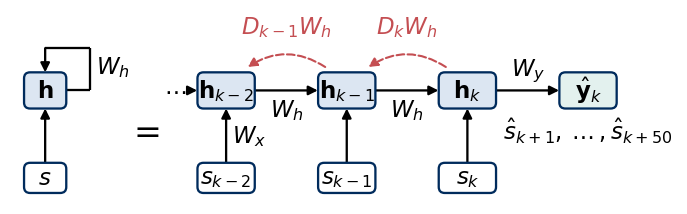

In [19]:
def box(ax, xy, text, w=0.9, h=0.6, fc="#DCE6F2", ec=UJNavy, fs=11, lw=1.1):
    # rounded box centred at xy
    ax.add_patch(FancyBboxPatch((xy[0] - w / 2, xy[1] - h / 2), w, h, boxstyle="round,pad=0.0,rounding_size=0.1",
                                fc=fc, ec=ec, lw=lw, zorder=3))
    ax.text(xy[0], xy[1], text, ha="center", va="center", fontsize=fs, zorder=4)

def op(ax, xy, sym, r=0.2, fs=11):
    # circle with an elementwise operation symbol
    ax.add_patch(Circle(xy, r, fc="white", ec="k", lw=1.0, zorder=3))
    ax.text(xy[0], xy[1], sym, ha="center", va="center", fontsize=fs, zorder=4)

def arrow(ax, pts, color="k", lw=1.1, ls="-", head=True):
    # polyline through the points pts; arrow head on the last segment
    pts = np.asarray(pts, float)
    for p0, p1 in zip(pts[:-2], pts[1:-1]):
        ax.plot([p0[0], p1[0]], [p0[1], p1[1]], color=color, lw=lw, ls=ls, zorder=2, solid_capstyle="butt")
    ax.annotate("", xy=pts[-1], xytext=pts[-2], zorder=2,
                arrowprops=dict(arrowstyle="-|>" if head else "-", color=color, lw=lw, ls=ls,
                                shrinkA=0, shrinkB=0, mutation_scale=9))

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.5))
    Y_H, Y_S = 1.9, 0.45
    # folded cell: input, hidden state with a self loop W_h
    box(ax, (0.6, Y_H), r"$\mathbf{h}$", w=0.7)
    box(ax, (0.6, Y_S), r"$s$", w=0.7, h=0.5, fc="white")
    arrow(ax, [(0.6, Y_S + 0.25), (0.6, Y_H - 0.3)])
    arrow(ax, [(0.95, Y_H), (1.35, Y_H), (1.35, 2.6), (0.6, 2.6), (0.6, Y_H + 0.3)])
    ax.text(1.45, 2.3, r"$W_h$", ha="left", va="center")
    ax.text(2.3, 1.2, "=", ha="center", va="center", fontsize=16)
    # unrolled network, one copy of the cell per time step
    xs, tags = [3.6, 5.6, 7.6], ["k-2", "k-1", "k"]
    for i, (x, t) in enumerate(zip(xs, tags)):
        box(ax, (x, Y_H), r"$\mathbf{h}_{" + t + "}$", w=0.95)
        box(ax, (x, Y_S), r"$s_{" + t + "}$", w=0.95, h=0.5, fc="white")
        arrow(ax, [(x, Y_S + 0.25), (x, Y_H - 0.3)])
    ax.text(xs[0] + 0.1, 1.15, r"$W_x$", ha="left", va="center")
    ax.text(2.75, Y_H, r"$\cdots$", ha="center", va="center")
    arrow(ax, [(3.0, Y_H), (xs[0] - 0.48, Y_H)])
    for x0, x1 in zip(xs[:-1], xs[1:]):
        arrow(ax, [(x0 + 0.48, Y_H), (x1 - 0.48, Y_H)])
        ax.text((x0 + x1) / 2, Y_H - 0.12, r"$W_h$", ha="center", va="top")
        # backward pass: the gradient flows from h_j to h_{j-1} through D_j W_h
        ax.annotate("", xy=(x0 + 0.3, Y_H + 0.35), xytext=(x1 - 0.3, Y_H + 0.35), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", connectionstyle="arc3,rad=0.35", color="#C44E52", lw=1.0,
                                    ls="--", mutation_scale=9))
    ax.text((xs[0] + xs[1]) / 2, 2.85, r"$D_{k-1}W_h$", ha="center", color="#C44E52")
    ax.text((xs[1] + xs[2]) / 2, 2.85, r"$D_kW_h$", ha="center", color="#C44E52")
    box(ax, (9.6, Y_H), r"$\hat{\mathbf{y}}_k$", w=0.95, fc="#E3F1EE")
    arrow(ax, [(xs[2] + 0.48, Y_H), (9.6 - 0.48, Y_H)]); ax.text(8.6, Y_H + 0.1, r"$W_y$", ha="center", va="bottom")
    ax.text(9.6, Y_H - 0.42, r"$\hat s_{k+1},\dots,\hat s_{k+50}$", ha="center", va="top")
    ax.set_xlim(0.1, 10.7); ax.set_ylim(0.1, 3.15); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_rnn_unrolled"); plt.show()

### Backpropagation through time

Gradient descent needs the derivative of the loss with respect to $W_h$, which enters every step. Applying the chain rule to the unrolled network gives backpropagation through time (BPTT). The loss depends on the last state $\mathbf h_k$, and a change of an earlier state $\mathbf h_j$ reaches $\mathbf h_k$ through the product of step Jacobians
$$\frac{\partial\mathbf h_k}{\partial\mathbf h_j}=\prod_{i=j+1}^{k}D_iW_h,\qquad D_i=\mathrm{diag}\big(1-\mathbf h_i^2\big),$$
where $D_i$ contains the derivatives $\tanh'=1-\tanh^2\in(0,1]$. The contribution of an input $m$ steps in the past to the gradient is multiplied by $m$ such factors. If the factors shrink vectors, the product decays exponentially and the network cannot learn from distant inputs. This is the vanishing gradient problem [Bengio, Simard and Frasconi, IEEE Trans. Neural Netw. **5**, 157 (1994), [doi:10.1109/72.279181](https://doi.org/10.1109/72.279181); Hochreiter and Schmidhuber, Neural Comput. **9**, 1735 (1997), [doi:10.1162/neco.1997.9.8.1735](https://doi.org/10.1162/neco.1997.9.8.1735)]. If the factors stretch vectors, the product grows exponentially and gradients explode [Pascanu, Mikolov and Bengio, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)]. Clipping the gradient norm, as in our training loop, limits the damage of exploding gradients and does nothing against vanishing ones.

We measure the norm $\|\partial\mathbf h_k/\partial\mathbf h_0\|_2$ (largest singular value) for random RNNs with $n_h=64$ driven by the Santa Fe signal. The recurrent matrix $W_h$ has Gaussian entries rescaled to the spectral radius $\rho\in\{0.5,1.0,1.5\}$ and $W_x$ has entries uniform in $[-1,1]$. For each $\rho$ we average $\log_{10}$ of the norm over 10 random networks. The Jacobian product is accumulated along the trajectory, and for one network we check it against `jax.jacfwd` of the map $\mathbf h_0\mapsto\mathbf h_k$.

check at k = 10: ||J||_2 accumulated = 1.095805e+00, jax.jacfwd = 1.095805e+00
rho = 0.5: mean log10 ||dh_k/dh_0|| at k = 10, 50, 100:   -2.86  -15.62  -31.64 | growth rate per step (k = 20..100): -0.736
rho = 1.0: mean log10 ||dh_k/dh_0|| at k = 10, 50, 100:   -0.06   -2.28   -5.13 | growth rate per step (k = 20..100): -0.129
rho = 1.5: mean log10 ||dh_k/dh_0|| at k = 10, 50, 100:    1.04    1.21    1.28 | growth rate per step (k = 20..100): +0.003


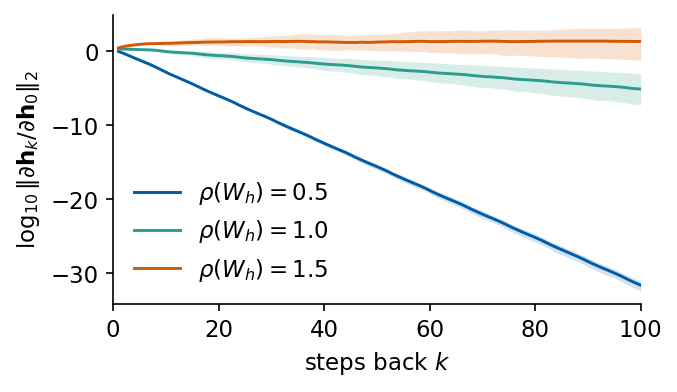

In [20]:
def rnn_jacobian_norms(W_h, w_x, u, h0):
    # accumulate J_k = D_k W_h J_{k-1} along the driven trajectory; returns ||J_k||_2 for k = 1..len(u)
    n = W_h.shape[0]
    def step(carry, uk):
        h, J = carry
        h = jnp.tanh(W_h @ h + w_x * uk)
        J = (1.0 - h ** 2)[:, None] * (W_h @ J)
        return (h, J), jnp.linalg.norm(J, 2)
    _, norms = jax.lax.scan(step, (h0, jnp.eye(n)), u)
    return norms

def rnn_map(h0, W_h, w_x, u):
    # h_0 -> h_k for the inputs u
    return jax.lax.scan(lambda h, uk: (jnp.tanh(W_h @ h + w_x * uk), None), h0, u)[0]

n_h_demo, K_DEMO, N_NETS = 64, 100, 10
u_demo = jnp.asarray(sig["SantaFe"][:K_DEMO])
log_norms = {}
for rho_ in (0.5, 1.0, 1.5):
    rows = []
    for seed in range(N_NETS):
        rng = np.random.default_rng(seed)
        W_h = rng.normal(size=(n_h_demo, n_h_demo)); W_h *= rho_ / np.max(np.abs(np.linalg.eigvals(W_h)))
        w_x = rng.uniform(-1, 1, n_h_demo)
        rows.append(np.log10(np.asarray(rnn_jacobian_norms(jnp.asarray(W_h), jnp.asarray(w_x), u_demo, jnp.zeros(n_h_demo)))))
        if seed == 0 and rho_ == 1.0:
            J_ad = jax.jacfwd(rnn_map)(jnp.zeros(n_h_demo), jnp.asarray(W_h), jnp.asarray(w_x), u_demo[:10])
            print(f"check at k = 10: ||J||_2 accumulated = {10 ** rows[-1][9]:.6e}, jax.jacfwd = {np.linalg.norm(J_ad, 2):.6e}")
    log_norms[rho_] = np.array(rows)

kk = np.arange(1, K_DEMO + 1)
fit_range = (kk >= 20)
nums["gradient_norm_rate"] = {}
for rho_, L_ in log_norms.items():
    slope = np.polyfit(kk[fit_range], L_.mean(0)[fit_range] * np.log(10), 1)[0]
    nums["gradient_norm_rate"][f"rho_{rho_}"] = float(slope)
    print(f"rho = {rho_}: mean log10 ||dh_k/dh_0|| at k = 10, 50, 100: {L_.mean(0)[9]:7.2f} {L_.mean(0)[49]:7.2f} "
          f"{L_.mean(0)[99]:7.2f} | growth rate per step (k = 20..100): {slope:+.3f}")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
    for (rho_, L_), c in zip(log_norms.items(), (UJBlue, "#2A9D8F", DSOrange)):
        ax.fill_between(kk, L_.min(0), L_.max(0), color=c, alpha=0.18, lw=0)
        ax.plot(kk, L_.mean(0), color=c, label=rf"$\rho(W_h)={rho_}$")
    ax.set_xlabel("steps back $k$"); ax.set_ylabel(r"$\log_{10}\|\partial\mathbf{h}_k/\partial\mathbf{h}_0\|_2$")
    ax.legend(loc="lower left"); ax.set_xlim(0, K_DEMO)
    save(fig, "fig_gradient_norms"); plt.show()

For $\rho=0.5$ the norm falls at the rate $-0.736$ per step in natural logarithm, a factor of about 2 per step, and after 100 steps it is $10^{-31.6}$. An input that far back has no influence on the gradient. For $\rho=1.0$ the decay is slower, with rate $-0.129$ per step, and still reaches $10^{-5.1}$ after 100 steps. For $\rho=1.5$ the norm grows to about $10^{1}$ within ten steps and then stays flat, with rate $+0.003$ per step and a wide spread between the ten networks. The saturation of tanh limits the growth here, since large states make the factors $D_i$ small. The spectral radius of $W_h$ alone does not fix the rate, which depends on the trajectory through the matrices $D_i$.

The Jacobian product is the tangent propagator of the hidden-state dynamics driven by the input, the object from which Lyapunov exponents are computed in the signals notebook, and the measured rate is a finite-time estimate of the largest Lyapunov exponent of this driven dynamics. Read as an analogy, vanishing gradients correspond to a contracting hidden dynamics with a negative exponent, exploding gradients to an expanding one with a positive exponent, and a network that should learn long dependencies has to sit close to the boundary between them.

<hr/>
## 6. Gated cells, LSTM and GRU

### Long short-term memory

The LSTM [Hochreiter and Schmidhuber, Neural Comput. **9**, 1735 (1997), [doi:10.1162/neco.1997.9.8.1735](https://doi.org/10.1162/neco.1997.9.8.1735)] adds a cell state $\mathbf c_k$ to the hidden state and controls it with three gates whose values lie in $(0,1)$. With the sigmoid $\sigma(a)=1/(1+e^{-a})$, the elementwise product $\odot$ and the concatenation $[\mathbf h_{k-1},s_k]$,
$$
\begin{aligned}
\mathbf f_k&=\sigma\big(W_f[\mathbf h_{k-1},s_k]+\mathbf b_f\big) &&\text{forget gate}\\
\mathbf i_k&=\sigma\big(W_i[\mathbf h_{k-1},s_k]+\mathbf b_i\big) &&\text{input gate}\\
\mathbf g_k&=\tanh\big(W_g[\mathbf h_{k-1},s_k]+\mathbf b_g\big) &&\text{candidate}\\
\mathbf o_k&=\sigma\big(W_o[\mathbf h_{k-1},s_k]+\mathbf b_o\big) &&\text{output gate}\\
\mathbf c_k&=\mathbf f_k\odot\mathbf c_{k-1}+\mathbf i_k\odot\mathbf g_k\\
\mathbf h_k&=\mathbf o_k\odot\tanh(\mathbf c_k).
\end{aligned}
$$
The forget gate decides how much of the cell state is kept, the input gate how much of the candidate is written, and the output gate how much of the cell is shown in $\mathbf h_k$. The cell state is updated by an elementwise product and a sum, with no matrix and no squashing function on the way from $\mathbf c_{k-1}$ to $\mathbf c_k$. Along this direct path the Jacobian is diagonal,
$$\left.\frac{\partial\mathbf c_k}{\partial\mathbf c_j}\right|_{\rm direct}=\prod_{i=j+1}^{k}\mathrm{diag}(\mathbf f_i).$$
In the original LSTM the cell had a self-connection of weight 1, so this factor was the identity, the constant error carousel through which errors flow back without decay. The forget gate, added by Gers, Schmidhuber and Cummins, makes the factor learnable [Neural Comput. **12**, 2451 (2000), [doi:10.1162/089976600300015015](https://doi.org/10.1162/089976600300015015)]. A unit with a constant forget value $f$ keeps a fraction $f^m=e^{-m/\tau_{\rm mem}}$ of its content after $m$ steps, a memory time
$$\tau_{\rm mem}=-\frac{1}{\ln f}.$$
For $f=0.9$ this is 9.5 steps and for $f=0.99$ it is 99.5 steps. Gers *et al.* recommend a positive initial forget bias so that the cell starts by keeping information. We initialise $\mathbf b_f=1$, which gives $f=\sigma(1)=0.73$ and $\tau_{\rm mem}=3.2$ steps at the start of training, and let the training lengthen it where the data require.

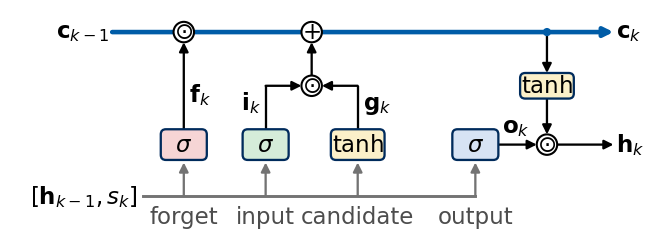

In [21]:
def draw_cell_frame(ax, x0, x1, y_top, label_in, label_out, y_bus, gates_x, bus_label):
    # common parts of the gated-cell drawings: state line on top and the input bus [h_{k-1}, s_k] below the gates
    arrow(ax, [(x0, y_top), (x1, y_top)], color=UJBlue, lw=2.2)
    ax.text(x0 - 0.05, y_top, label_in, ha="right", va="center")
    ax.text(x1 + 0.05, y_top, label_out, ha="left", va="center")
    ax.plot([x0 + 0.6, max(gates_x)], [y_bus, y_bus], color="0.45", lw=1.4, zorder=2)
    ax.text(x0 + 0.5, y_bus, bus_label, ha="right", va="center")
    for gx in gates_x:
        arrow(ax, [(gx, y_bus), (gx, y_bus + 0.65)], color="0.45")

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.75))
    Y_TOP, Y_G, Y_BUS = 3.8, 1.6, 0.6
    GX = {"f": 2.4, "i": 4.0, "g": 5.8, "o": 8.1}
    draw_cell_frame(ax, 1.0, 10.8, Y_TOP, r"$\mathbf{c}_{k-1}$", r"$\mathbf{c}_k$", Y_BUS, GX.values(),
                    r"$[\mathbf{h}_{k-1},s_k]$")
    for key, fc, txt in (("f", "#F6D5D5", r"$\sigma$"), ("i", "#D5ECD9", r"$\sigma$"), ("g", "#FBF0C9", r"$\tanh$"),
                         ("o", "#D7E3F4", r"$\sigma$")):
        box(ax, (GX[key], Y_G), txt, w=1.05 if key == "g" else 0.9, h=0.6, fc=fc)
    op(ax, (GX["f"], Y_TOP), r"$\odot$")                  # forget: c_{k-1} * f_k
    op(ax, (4.9, Y_TOP), r"$+$")                          # add the written candidate
    op(ax, (4.9, 2.75), r"$\odot$")                       # i_k * g_k
    arrow(ax, [(GX["f"], Y_G + 0.3), (GX["f"], Y_TOP - 0.2)]); ax.text(GX["f"] + 0.1, 2.45, r"$\mathbf{f}_k$", ha="left")
    arrow(ax, [(GX["i"], Y_G + 0.3), (GX["i"], 2.75), (4.7, 2.75)]); ax.text(GX["i"] - 0.1, 2.3, r"$\mathbf{i}_k$", ha="right")
    arrow(ax, [(GX["g"], Y_G + 0.3), (GX["g"], 2.75), (5.1, 2.75)]); ax.text(GX["g"] + 0.1, 2.3, r"$\mathbf{g}_k$", ha="left")
    arrow(ax, [(4.9, 2.95), (4.9, Y_TOP - 0.2)])
    # output branch: tanh(c_k) * o_k -> h_k
    ax.add_patch(Circle((9.5, Y_TOP), 0.06, color=UJBlue, zorder=4))
    box(ax, (9.5, 2.75), r"$\tanh$", w=1.05, h=0.5, fc="#FBF0C9")
    arrow(ax, [(9.5, Y_TOP), (9.5, 3.0)])
    op(ax, (9.5, Y_G), r"$\odot$")
    arrow(ax, [(9.5, 2.5), (9.5, Y_G + 0.2)])
    arrow(ax, [(GX["o"] + 0.45, Y_G), (9.3, Y_G)]); ax.text(8.9, Y_G + 0.12, r"$\mathbf{o}_k$", ha="center", va="bottom")
    arrow(ax, [(9.7, Y_G), (10.8, Y_G)]); ax.text(10.85, Y_G, r"$\mathbf{h}_k$", ha="left", va="center")
    for key, name in (("f", "forget"), ("i", "input"), ("g", "candidate"), ("o", "output")):
        ax.text(GX[key], Y_BUS - 0.18, name, ha="center", va="top", color="0.3")
    ax.set_xlim(-0.9, 11.6); ax.set_ylim(-0.05, 4.15); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lstm_cell"); plt.show()

In the drawing of the LSTM cell the cell state is the blue line at the top. It is touched only by the elementwise operations $\odot$ and $+$, so gradients can travel along it for many steps when $\mathbf f_k$ is close to 1.

### Gated recurrent unit

The GRU [Cho *et al.*, EMNLP (2014), [doi:10.3115/v1/D14-1179](https://doi.org/10.3115/v1/D14-1179)] merges the cell and hidden states and uses two gates. We write it in the convention of Cho *et al.* and of the libraries (`flax.nnx.GRUCell`, PyTorch), where the update gate $\mathbf z_k$ multiplies the old state,
$$
\begin{aligned}
\mathbf r_k&=\sigma\big(W_{ir}s_k+\mathbf b_{ir}+W_{hr}\mathbf h_{k-1}\big) &&\text{reset gate}\\
\mathbf z_k&=\sigma\big(W_{iz}s_k+\mathbf b_{iz}+W_{hz}\mathbf h_{k-1}\big) &&\text{update gate}\\
\mathbf n_k&=\tanh\big(W_{in}s_k+\mathbf b_{in}+\mathbf r_k\odot(W_{hn}\mathbf h_{k-1})\big) &&\text{candidate}\\
\mathbf h_k&=(1-\mathbf z_k)\odot\mathbf n_k+\mathbf z_k\odot\mathbf h_{k-1}.
\end{aligned}
$$
Other texts use the complementary convention, in which $\mathbf z_k$ multiplies the candidate. The two are related by $\mathbf z\to1-\mathbf z$. With $z_k\to1$ a unit keeps its old value, and along this path $\partial\mathbf h_k/\partial\mathbf h_{k-1}|_{\rm direct}=\mathrm{diag}(\mathbf z_k)$, the analogue of the LSTM forget gate. The reset gate $\mathbf r_k$ decides how much of the old state enters the candidate. In the libraries it multiplies $W_{hn}\mathbf h_{k-1}$, while the paper of Cho *et al.* applies it before the matrix, $W_{hn}(\mathbf r_k\odot\mathbf h_{k-1})$. We use the library form so that our cell can be checked against `nnx.GRUCell`.

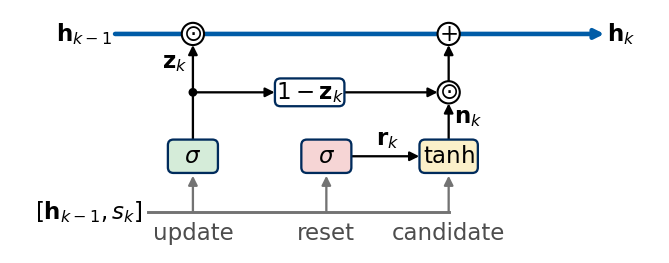

In [22]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.75))
    Y_TOP, Y_G, Y_BUS = 3.8, 1.6, 0.6
    GX = {"z": 2.6, "r": 5.0, "n": 7.2}
    draw_cell_frame(ax, 1.2, 10.0, Y_TOP, r"$\mathbf{h}_{k-1}$", r"$\mathbf{h}_k$", Y_BUS, GX.values(),
                    r"$[\mathbf{h}_{k-1},s_k]$")
    box(ax, (GX["z"], Y_G), r"$\sigma$", fc="#D5ECD9")
    box(ax, (GX["r"], Y_G), r"$\sigma$", fc="#F6D5D5")
    box(ax, (GX["n"], Y_G), r"$\tanh$", w=1.05, fc="#FBF0C9")
    op(ax, (GX["z"], Y_TOP), r"$\odot$")                  # z_k * h_{k-1}
    op(ax, (GX["n"], Y_TOP), r"$+$")
    op(ax, (GX["n"], 2.75), r"$\odot$")                   # (1 - z_k) * n_k
    arrow(ax, [(GX["z"], Y_G + 0.3), (GX["z"], Y_TOP - 0.2)]); ax.text(GX["z"] - 0.1, 3.2, r"$\mathbf{z}_k$", ha="right")
    ax.add_patch(Circle((GX["z"], 2.75), 0.06, color="k", zorder=4))
    box(ax, (4.7, 2.75), r"$1-\mathbf{z}_k$", w=1.25, h=0.5, fc="white")
    arrow(ax, [(GX["z"], 2.75), (4.07, 2.75)]); arrow(ax, [(5.33, 2.75), (GX["n"] - 0.2, 2.75)])
    arrow(ax, [(GX["r"] + 0.45, Y_G), (GX["n"] - 0.53, Y_G)]); ax.text(6.1, Y_G + 0.1, r"$\mathbf{r}_k$", ha="center", va="bottom")
    arrow(ax, [(GX["n"], Y_G + 0.3), (GX["n"], 2.55)]); ax.text(GX["n"] + 0.1, 2.2, r"$\mathbf{n}_k$", ha="left")
    arrow(ax, [(GX["n"], 2.95), (GX["n"], Y_TOP - 0.2)])
    for key, name in (("z", "update"), ("r", "reset"), ("n", "candidate")):
        ax.text(GX[key], Y_BUS - 0.18, name, ha="center", va="top", color="0.3")
    ax.set_xlim(-0.6, 10.9); ax.set_ylim(-0.05, 4.15); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_gru_cell"); plt.show()

### Parameter counts

For an input of dimension $n_x$ every gate or candidate of the LSTM has a matrix acting on $[\mathbf h_{k-1},s_k]$ and a bias, $n_h^2+n_hn_x+n_h$ parameters, and there are four of them. The GRU has three such blocks and the vanilla RNN one,
$$P_{\rm LSTM}=4(n_h^2+n_hn_x+n_h),\qquad P_{\rm GRU}=3(n_h^2+n_hn_x+n_h),\qquad P_{\rm RNN}=n_h^2+n_hn_x+n_h,$$
plus $50(n_h+1)$ for the readout to 50 leads. We use $n_h=32$ and $n_x=1$, and the counts are checked against the implemented modules in Section 7.

<hr/>
## 7. Recurrent cells in flax.nnx

We implement the three cells as `nnx.Module` classes with one method, `cell(carry, s_k) -> (carry, h_k)`, the signature of the library cells. The carry is $\mathbf h$ for the RNN and the GRU and the pair $(\mathbf c,\mathbf h)$ for the LSTM. A cell acts on a batch, so $s_k$ has shape $(B,1)$ and $\mathbf h$ shape $(B,n_h)$. A separate module `Recurrent` runs any cell over the window with `jax.lax.scan`, which compiles the loop over the $L$ time steps once, and applies the linear readout to the last hidden state. The input window has shape $(B,L,1)$, and scan iterates over the leading axis, so we swap the batch and time axes before the loop.

The initialisation follows the libraries. Input matrices use the LeCun normal distribution, recurrent matrices of the RNN and the GRU a random orthogonal matrix, whose singular values are all 1, so that the initial Jacobian product neither shrinks nor grows through $W_h$, and the LSTM gets the forget bias $\mathbf b_f=1$.

In [23]:
orthogonal = nnx.initializers.orthogonal()

class RNNCell(nnx.Module):
    # h_k = tanh(W_x s_k + b + W_h h_{k-1})
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.Wx = nnx.Linear(n_x, n_h, rngs=rngs)                                   # W_x and b
        self.Wh = nnx.Linear(n_h, n_h, use_bias=False, kernel_init=orthogonal, rngs=rngs)
    def init_carry(self, B, dtype):
        return jnp.zeros((B, self.n_h), dtype)
    def __call__(self, h, s):
        h = jnp.tanh(self.Wx(s) + self.Wh(h))
        return h, h

class GRUCell(nnx.Module):
    # library convention: h_k = (1 - z) * n + z * h_{k-1}, reset gate applied after W_hn
    def __init__(self, n_x, n_h, *, rngs):
        self.n_h = n_h
        self.Wi = nnx.Linear(n_x, 3 * n_h, rngs=rngs)                               # [W_ir, W_iz, W_in] and biases
        self.Wh = nnx.Linear(n_h, 3 * n_h, use_bias=False, kernel_init=orthogonal, rngs=rngs)   # [W_hr, W_hz, W_hn]
    def init_carry(self, B, dtype):
        return jnp.zeros((B, self.n_h), dtype)
    def __call__(self, h, s):
        xr, xz, xn = jnp.split(self.Wi(s), 3, axis=-1)
        hr, hz, hn = jnp.split(self.Wh(h), 3, axis=-1)
        r = jax.nn.sigmoid(xr + hr)                     # reset gate
        z = jax.nn.sigmoid(xz + hz)                     # update gate
        n = jnp.tanh(xn + r * hn)                       # candidate
        h = (1.0 - z) * n + z * h
        return h, h

class LSTMCell(nnx.Module):
    # one matrix on the concatenation [h_{k-1}, s_k] for the four blocks (i, f, g, o)
    def __init__(self, n_x, n_h, *, rngs, forget_bias=1.0):
        self.n_h = n_h
        self.W = nnx.Linear(n_h + n_x, 4 * n_h, rngs=rngs)
        self.W.bias[...] = self.W.bias[...].at[n_h:2 * n_h].set(forget_bias)      # b_f = 1 (Gers et al. 2000)
    def init_carry(self, B, dtype):
        return (jnp.zeros((B, self.n_h), dtype), jnp.zeros((B, self.n_h), dtype))
    def gates(self, carry, s):
        c, h = carry
        a_i, a_f, a_g, a_o = jnp.split(self.W(jnp.concatenate([h, s], axis=-1)), 4, axis=-1)
        return jax.nn.sigmoid(a_i), jax.nn.sigmoid(a_f), jnp.tanh(a_g), jax.nn.sigmoid(a_o)
    def __call__(self, carry, s):
        c, h = carry
        i, f, g, o = self.gates(carry, s)
        c = f * c + i * g                               # cell state: elementwise only
        h = o * jnp.tanh(c)
        return (c, h), h

class Recurrent(nnx.Module):
    # any cell run over the window, linear readout of the last hidden state to the 50 leads
    def __init__(self, cell, n_h, n_out, *, rngs):
        self.cell = cell
        self.head = nnx.Linear(n_h, n_out, rngs=rngs)    # W_y, b_y
    def hidden_states(self, V):
        # V: (B, L, 1) -> all hidden states (L, B, n_h)
        carry = self.cell.init_carry(V.shape[0], V.dtype)
        _, hs = jax.lax.scan(lambda c, s: self.cell(c, s), carry, jnp.swapaxes(V, 0, 1))
        return hs
    def __call__(self, V):
        return self.head(self.hidden_states(V)[-1])

N_H = 32
CELLS = {"RNN": RNNCell, "GRU": GRUCell, "LSTM": LSTMCell}

def make_model(kind, seed, L=L_WIN, n_h=N_H):
    rngs = nnx.Rngs(seed)
    if kind == "MLP":
        return MLP(L, N_MLP, TAU_MAX, rngs=rngs)
    return Recurrent(CELLS[kind](1, n_h, rngs=rngs), n_h, TAU_MAX, rngs=rngs)

V_try = data_sf[0][:4]
for kind in ("MLP", "RNN", "GRU", "LSTM"):
    m = make_model(kind, 0)
    out = m(V_try)
    assert out.shape == (4, TAU_MAX)
    print(f"{kind:5s} output {out.shape}, parameters {n_params(m)}")

MLP   output (4, 50), parameters 7410
RNN   output (4, 50), parameters 2738
GRU   output (4, 50), parameters 4914
LSTM  output (4, 50), parameters 6002


### Check against the library cells

Flax provides `nnx.SimpleCell`, `nnx.GRUCell` and `nnx.LSTMCell` with the same equations and a different storage of the weights. The library GRU keeps the input and recurrent matrices of the three blocks side by side in the order $(r,z,n)$, as ours does. The library LSTM keeps eight separate matrices, `ii, if_, ig, io` for the input and `hi, hf, hg, ho` for the hidden state, with the biases on the hidden side. We copy the library weights into our cells and run both on the same random sequence of length 64 and batch size 8.

In [24]:
def run_cell(cell, carry, S):
    # S: (L, B, n_x) -> hidden states (L, B, n_h)
    return jax.lax.scan(lambda c, s: cell(c, s), carry, S)[1]

n_x, n_hc, B_chk, L_chk = 1, N_H, 8, 64
S_chk = jax.random.uniform(jax.random.key(3), (L_chk, B_chk, n_x), jnp.float32)

lib = nnx.SimpleCell(n_x, n_hc, rngs=nnx.Rngs(1)); own = RNNCell(n_x, n_hc, rngs=nnx.Rngs(2))
own.Wx.kernel[...] = lib.dense_i.kernel[...]; own.Wx.bias[...] = lib.dense_i.bias[...]
own.Wh.kernel[...] = lib.dense_h.kernel[...]
h0 = jnp.zeros((B_chk, n_hc), jnp.float32)
print("RNN  max |h_own - h_flax| =", float(jnp.abs(run_cell(own, h0, S_chk) - run_cell(lib, h0, S_chk)).max()))

lib = nnx.GRUCell(n_x, n_hc, rngs=nnx.Rngs(1)); own = GRUCell(n_x, n_hc, rngs=nnx.Rngs(2))
own.Wi.kernel[...] = lib.dense_i.kernel[...]; own.Wi.bias[...] = lib.dense_i.bias[...]
own.Wh.kernel[...] = lib.dense_h.kernel[...]
print("GRU  max |h_own - h_flax| =", float(jnp.abs(run_cell(own, h0, S_chk) - run_cell(lib, h0, S_chk)).max()))

lib = nnx.LSTMCell(n_x, n_hc, rngs=nnx.Rngs(1)); own = LSTMCell(n_x, n_hc, rngs=nnx.Rngs(2))
K_h = jnp.concatenate([getattr(lib, a).kernel[...] for a in ("hi", "hf", "hg", "ho")], axis=1)   # (n_h, 4 n_h)
K_i = jnp.concatenate([getattr(lib, a).kernel[...] for a in ("ii", "if_", "ig", "io")], axis=1)  # (n_x, 4 n_h)
own.W.kernel[...] = jnp.concatenate([K_h, K_i], axis=0)                                         # rows: [h, s]
own.W.bias[...] = jnp.concatenate([getattr(lib, a).bias[...] for a in ("hi", "hf", "hg", "ho")])
c0 = (h0, h0)
print("LSTM max |h_own - h_flax| =", float(jnp.abs(run_cell(own, c0, S_chk) - run_cell(lib, c0, S_chk)).max()))

counts = {"RNN": (n_hc ** 2 + n_hc * n_x + n_hc), "GRU": 3 * (n_hc ** 2 + n_hc * n_x + n_hc),
          "LSTM": 4 * (n_hc ** 2 + n_hc * n_x + n_hc)}
for kind, P in counts.items():
    cell = CELLS[kind](n_x, n_hc, rngs=nnx.Rngs(0))
    assert n_params(cell) == P
    print(f"{kind:5s} cell parameters: formula {P}, module {n_params(cell)}, with readout {P + TAU_MAX * (n_hc + 1)}")
nums["param_counts"] = {k: P + TAU_MAX * (n_hc + 1) for k, P in counts.items()}
nums["param_counts"]["MLP"] = n_params(make_model("MLP", 0))
f0 = 1 / (1 + np.exp(-1.0))
print(f"forget gate at initialisation f = sigma(1) = {f0:.3f}, memory time -1/ln f = {-1 / np.log(f0):.2f} steps;"
      f" f = 0.9 -> {-1 / np.log(0.9):.1f}, f = 0.99 -> {-1 / np.log(0.99):.1f}")

RNN  max |h_own - h_flax| = 0.0
GRU  max |h_own - h_flax| = 0.0
LSTM max |h_own - h_flax| = 0.0
RNN   cell parameters: formula 1088, module 1088, with readout 2738
GRU   cell parameters: formula 3264, module 3264, with readout 4914
LSTM  cell parameters: formula 4352, module 4352, with readout 6002
forget gate at initialisation f = sigma(1) = 0.731, memory time -1/ln f = 3.19 steps; f = 0.9 -> 9.5, f = 0.99 -> 99.5


`nnx.tabulate` lists the submodules of a model with the shapes of their outputs and parameters, and we apply it to the LSTM forecaster on a batch of two windows.

In [25]:
print(nnx.tabulate(make_model("LSTM", 0), data_sf[0][:2], depth=2, console_kwargs={"width": 120}))

                                       Recurrent Summary                                        
┏━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ path            ┃ type      ┃ inputs            ┃ outputs          ┃ Param                   ┃
┡━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ hidden_states   │ Recurrent │ float32[2,64,1]   │ float32[64,2,32] │ 6,002 (24.0 KB)         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ cell/init_carry │ LSTMCell  │ - 2               │ - float32[2,32]  │ 4,352 (17.4 KB)         │
│                 │           │ - dtype(float32)  │ - float32[2,32]  │                         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ cell/gates      │ LSTMCell  │ - - float32[2,32] │ - float32[2,32]  │ 4,352 (17.4 KB)         │
│                 │           │   - float32[2,32] │ - float32[2,32]  │                         │
│                 │           │ - float32[2,1]    │ - float32[2,32]  │                         │
│                 │           │                   │ - float32[2,32]  │                         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ cell/W          │ Linear    │ float32[2,33]     │ float32[2,128]   │ bias: float32[128]      │
│                 │           │                   │                  │ kernel: float32[33,128] │
│                 │           │                   │                  │                         │
│                 │           │                   │                  │ 4,352 (17.4 KB)         │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│ head            │ Linear    │ float32[2,32]     │ float32[2,50]    │ bias: float32[50]       │
│                 │           │                   │                  │ kernel: float32[32,50]  │
│                 │           │                   │                  │                         │
│                 │           │                   │                  │ 1,650 (6.6 KB)          │
├─────────────────┼───────────┼───────────────────┼──────────────────┼─────────────────────────┤
│                 │           │                   │            Total │ 6,002 (24.0 KB)         │
└─────────────────┴───────────┴───────────────────┴──────────────────┴─────────────────────────┘
                                                                                                
                               Total Parameters: 6,002 (24.0 KB)                                

<hr/>
## 8. Training recurrent networks

### Scaling of the input

The tanh units of a recurrent network respond to inputs of order one. The Santa Fe intensity is recorded as integers up to 255, and fed to the network without rescaling it drives almost every unit into saturation, where $\tanh'\approx0$ and the gradient vanishes at the first step. We count the fraction of hidden values with $|h|>0.99$ for an untrained RNN on the test windows, once for the raw and once for the rescaled signal.

In [26]:
rnn0 = make_model("RNN", 0)
U_raw, _ = windows(raw["SantaFe"], K_TEST)
for lab, V in (("raw intensity", U_raw), ("rescaled to [0, 1]", windows(sig["SantaFe"], K_TEST)[0])):
    hs = rnn0.hidden_states(jnp.asarray(V[..., None], jnp.float32))
    frac = float(jnp.mean(jnp.abs(hs) > 0.99))
    nums.setdefault("saturation", {})[lab] = frac
    print(f"{lab:20s}: fraction of saturated hidden values |h| > 0.99 = {frac:.3f}")

raw intensity       : fraction of saturated hidden values |h| > 0.99 = 0.991
rescaled to [0, 1]  : fraction of saturated hidden values |h| > 0.99 = 0.000


With the raw intensity 99.1% of the hidden values are saturated, and with the rescaled signal none are. All signals are therefore rescaled to $[0,1]$ with the training block, as in the notebook on linear models.

### Training on the Santa Fe laser

We train the four networks on the Santa Fe signal with seed 0 and look at the loss curves. The training loss is averaged over the minibatches of an epoch while the weights change, and the validation loss is computed after the epoch.

MLP   250 epochs (best 244),   2.3 s, val loss 1.12e-02, median gradient norm 0.026, clipped steps 0.0%, test C_tot = 35.3
RNN   221 epochs (best 201),  16.2 s, val loss 5.10e-03, median gradient norm 0.110, clipped steps 0.0%, test C_tot = 42.5
GRU   221 epochs (best 201),  46.2 s, val loss 4.28e-03, median gradient norm 0.038, clipped steps 0.0%, test C_tot = 43.0
LSTM  222 epochs (best 202),  53.2 s, val loss 3.99e-03, median gradient norm 0.088, clipped steps 0.0%, test C_tot = 44.3


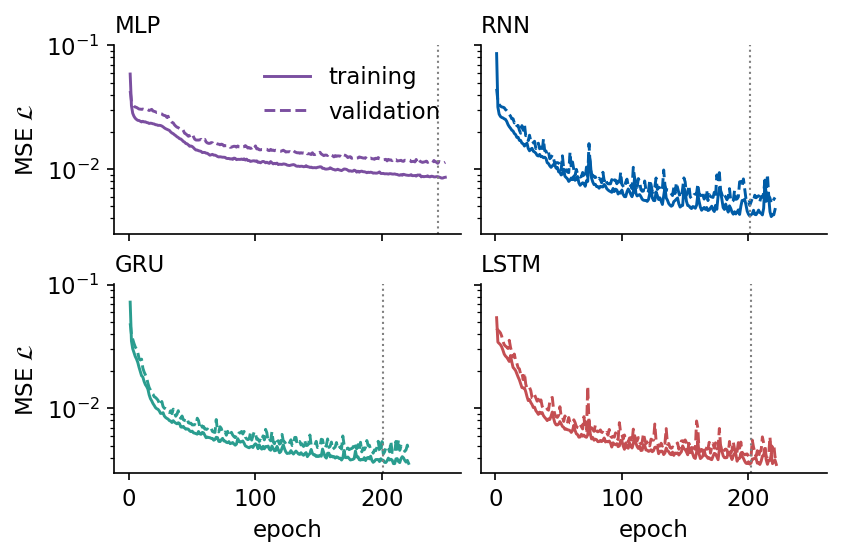

In [27]:
MODELS = ("MLP", "RNN", "GRU", "LSTM")
nets, hists = {name: {} for name in SIGNALS}, {name: {} for name in SIGNALS}
data = {name: net_data(sig[name]) for name in SIGNALS}

def train_and_score(name, kind, seed=0):
    m, h = fit_network(make_model(kind, seed), data[name][:4], seed=seed, verbose=False)
    out = dict(pred=predict(m, data[name][4]), time=h["time"], epochs=h["epochs_run"], best_epoch=h["best_epoch"],
               n_params=n_params(m), **score(predict(m, data[name][4]), np.asarray(data[name][5], np.float64)))
    return m, h, out

for kind in MODELS:
    nets["SantaFe"][kind], hists["SantaFe"][kind], res["SantaFe"][kind] = train_and_score("SantaFe", kind)
    h, r_ = hists["SantaFe"][kind], res["SantaFe"][kind]
    print(f"{kind:5s} {h['epochs_run']:3d} epochs (best {h['best_epoch']:3d}), {h['time']:5.1f} s,"
          f" val loss {h['best_val']:.2e}, median gradient norm {np.median(h['gnorm']):.3f},"
          f" clipped steps {100 * np.mean(h['clipped']):.1f}%, test C_tot = {r_['Ctot']:.1f}")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 2, figsize=(5.5, 3.6), sharex=True, sharey=True, layout="constrained")
    for ax, kind in zip(axs.ravel(), MODELS):
        h = hists["SantaFe"][kind]
        ep = np.arange(1, h["epochs_run"] + 1)
        ax.semilogy(ep, h["train"], color=STYLE[kind]["color"], label="training")
        ax.semilogy(ep, h["val"], color=STYLE[kind]["color"], ls="--", label="validation")
        ax.axvline(h["best_epoch"], color="0.5", ls=":", lw=1.0)
        ax.set_title(kind, loc="left", fontsize=11)
    for ax in axs[1]: ax.set_xlabel("epoch")
    for ax in axs[:, 0]: ax.set_ylabel(r"MSE $\mathcal{L}$")
    axs[0, 0].legend(loc="upper right")
    save(fig, "fig_training_curves"); plt.show()
nums["santafe_training"] = {k: dict(epochs=int(hists["SantaFe"][k]["epochs_run"]), best_epoch=int(hists["SantaFe"][k]["best_epoch"]),
                                    time_s=float(hists["SantaFe"][k]["time"]), clipped_frac=float(np.mean(hists["SantaFe"][k]["clipped"])),
                                    median_gnorm=float(np.median(hists["SantaFe"][k]["gnorm"])))
                            for k in MODELS}

The training loss falls fast in the first few tens of epochs and slowly afterwards, and the validation loss follows it at a slightly higher level. The recurrent networks reach lower losses than the MLP, with best validation losses of $1.12\times10^{-2}$ (MLP), $5.10\times10^{-3}$ (RNN), $4.28\times10^{-3}$ (GRU) and $3.99\times10^{-3}$ (LSTM). Early stopping ended the RNN, GRU and LSTM runs after 221 or 222 epochs, with the best epochs 201 or 202, while the MLP used the full 250 epochs. The occasional spikes of the validation loss last one or two epochs, and keeping the best parameters makes the result insensitive to them. With 2387 overlapping training windows and at most 6002 parameters, the gap between training and validation loss stays small, so overfitting is weak at these sizes. Gradient clipping was never active in these runs. The median gradient norm per epoch was between 0.026 and 0.110, far below the threshold 1, and clipping acts here only as a safeguard.

### Memory times of the trained LSTM

The forget gates of the trained LSTM tell which memory times it uses. For every unit we average $f$ over all steps of the test windows and convert the mean to $\tau_{\rm mem}=-1/\ln\bar f$.

Santa Fe LSTM, 32 units: memory time median 2.5, min 1.1, max 3.5 steps; units with tau_mem > 10 steps: 0


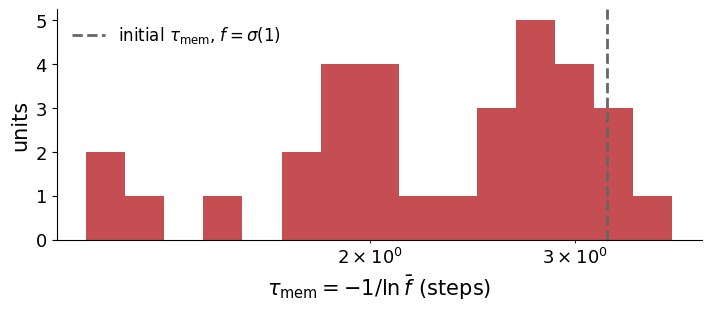

In [28]:
def lstm_forget_values(model, V):
    # forget-gate values f_k of all units along the windows V: (L, B, n_h)
    cell = model.cell
    def step(carry, s):
        i, f, g, o = cell.gates(carry, s)
        c = f * carry[0] + i * g
        return (c, o * jnp.tanh(c)), f
    return jax.lax.scan(step, cell.init_carry(V.shape[0], V.dtype), jnp.swapaxes(V, 0, 1))[1]

f_mean = np.asarray(lstm_forget_values(nets["SantaFe"]["LSTM"], data["SantaFe"][4]).mean(axis=(0, 1)))
tau_mem = -1 / np.log(f_mean)
nums["lstm_santafe_tau_mem"] = dict(median=float(np.median(tau_mem)), max=float(tau_mem.max()), min=float(tau_mem.min()),
                                   n_above_10=int((tau_mem > 10).sum()))
print(f"Santa Fe LSTM, {N_H} units: memory time median {np.median(tau_mem):.1f}, min {tau_mem.min():.1f},"
      f" max {tau_mem.max():.1f} steps; units with tau_mem > 10 steps: {(tau_mem > 10).sum()}")
fig, ax = plt.subplots(figsize=(7, 3), layout="constrained")
ax.hist(tau_mem, bins=np.logspace(np.log10(max(tau_mem.min(), 0.3)), np.log10(tau_mem.max() * 1.05), 16), color=STYLE["LSTM"]["color"])
ax.axvline(-1 / np.log(f0), color="0.4", ls="--", label=r"initial $\tau_{\rm mem}$, $f=\sigma(1)$")
ax.set_xscale("log"); ax.set_xlabel(r"$\tau_{\rm mem}=-1/\ln\bar f$ (steps)"); ax.set_ylabel("units"); ax.legend()
plt.show()

The trained LSTM uses short memory times. The median over the 32 units is 2.5 steps and the largest value 3.5 steps, so the median lies below the initial 3.2 steps. On the Santa Fe signal the network has learned to forget fast and to compute its forecast from the last few values, and the long memory path of the LSTM is unused. The forget gate is a learnable time constant, and the data set it.

### Window length and hidden size

The window length $L$ and the hidden size $n_h$ are hyperparameters. The window has to cover the memory the signal requires, and in the signals notebook the delay embedding of Santa Fe gave an estimate of that scale. The hidden size sets the capacity of the model and, with it, the risk of overfitting. We train the GRU on Santa Fe for a few combinations. The choice is made on the validation loss, and we print the test $C_{\rm tot}$ only to show how far the two agree.

In [29]:
scan_rows = []
for L_, nh_ in ((16, 32), (32, 32), (64, 8), (64, 32), (64, 64)):
    if (L_, nh_) == (L_WIN, N_H):
        h, r_ = hists["SantaFe"]["GRU"], res["SantaFe"]["GRU"]
        row = dict(L=L_, n_h=nh_, params=r_["n_params"], val=h["best_val"], Ctot=r_["Ctot"], time=h["time"])
    else:
        d_ = net_data(sig["SantaFe"], L=L_)
        m, h = fit_network(make_model("GRU", 0, L=L_, n_h=nh_), d_[:4], seed=0, verbose=False)
        row = dict(L=L_, n_h=nh_, params=n_params(m), val=h["best_val"], time=h["time"],
                   Ctot=score(predict(m, d_[4]), np.asarray(d_[5], np.float64))["Ctot"])
    scan_rows.append(row)
    print(f"GRU L = {row['L']:2d}, n_h = {row['n_h']:2d}: {row['params']:5d} parameters, best validation loss {row['val']:.2e},"
          f" test C_tot = {row['Ctot']:.1f}, {row['time']:.0f} s")
nums["gru_scan"] = scan_rows

GRU L = 16, n_h = 32:  4914 parameters, best validation loss 4.15e-03, test C_tot = 43.8, 15 s
GRU L = 32, n_h = 32:  4914 parameters, best validation loss 3.93e-03, test C_tot = 44.3, 27 s
GRU L = 64, n_h =  8:   690 parameters, best validation loss 1.18e-02, test C_tot = 35.0, 15 s
GRU L = 64, n_h = 32:  4914 parameters, best validation loss 4.28e-03, test C_tot = 43.0, 46 s
GRU L = 64, n_h = 64: 15922 parameters, best validation loss 2.95e-03, test C_tot = 44.1, 73 s


A hidden size of 8 is too small (best validation loss $1.18\times10^{-2}$, test $C_{\rm tot}=35.0$), while 32 and 64 units give similar test results. The window of 16 values is nearly as good as 64 ($C_{\rm tot}=43.8$ against $43.0$), consistent with the short memory times of the trained LSTM, and uses a quarter as many recurrent steps per window. The lowest validation loss belongs to $L=64$, $n_h=64$, which would be the choice made on validation data, with test $C_{\rm tot}=44.1$. The differences between the larger settings are below one unit of $C_{\rm tot}$, comparable to the measured seed spread, so this scan supports the conclusion that a few tens of units suffice and does not rank the larger settings.

### Seed dependence

The result of a network depends on the random initial weights and on the order of the minibatches, both fixed by the seed. We repeat the Santa Fe training with two more seeds for every network.

In [30]:
seed_ctot = {k: [res["SantaFe"][k]["Ctot"]] for k in MODELS}
for kind in MODELS:
    for seed in (1, 2):
        seed_ctot[kind].append(train_and_score("SantaFe", kind, seed)[2]["Ctot"])
    v = np.array(seed_ctot[kind])
    print(f"{kind:5s} Santa Fe C_tot for seeds 0, 1, 2: " + ", ".join(f"{x:.1f}" for x in v)
          + f"  (mean {v.mean():.1f}, range {v.max() - v.min():.1f})")
nums["santafe_seeds_Ctot"] = {k: [float(x) for x in v] for k, v in seed_ctot.items()}

MLP   Santa Fe C_tot for seeds 0, 1, 2: 35.3, 35.6, 36.0  (mean 35.6, range 0.6)
RNN   Santa Fe C_tot for seeds 0, 1, 2: 42.5, 41.6, 42.2  (mean 42.1, range 0.9)
GRU   Santa Fe C_tot for seeds 0, 1, 2: 43.0, 43.5, 43.0  (mean 43.2, range 0.5)
LSTM  Santa Fe C_tot for seeds 0, 1, 2: 44.3, 44.0, 44.9  (mean 44.4, range 0.9)


Over three seeds the Santa Fe $C_{\rm tot}$ varies by at most 0.9 for every network. The means are 35.6 (MLP), 42.1 (RNN), 43.2 (GRU) and 44.4 (LSTM), and the seed ranges of RNN, GRU and LSTM do not overlap. For this signal, these sizes and this training protocol, the order LSTM > GRU > RNN is therefore stable against the seed, and the step from the MLP to any recurrent network is several times larger than the seed spread. All other signals are trained with seed 0 only, and differences below about one unit of $C_{\rm tot}$ between networks are within the seed spread measured here.

### All signals

The same four networks, with the same settings and seed 0, are now trained on the other four signals.

In [31]:
t0 = time.time()
for name in SIGNALS:
    if name == "SantaFe":
        continue
    for kind in MODELS:
        nets[name][kind], hists[name][kind], res[name][kind] = train_and_score(name, kind)
    print(f"{name:8s} " + " | ".join(f"{k} C_tot {res[name][k]['Ctot']:5.1f} ({res[name][k]['epochs']} ep, {res[name][k]['time']:.0f} s)"
                                     for k in MODELS))
print(f"training time for four signals: {time.time() - t0:.0f} s")

Lorenz   MLP C_tot  29.4 (192 ep, 2 s) | RNN C_tot  43.8 (185 ep, 13 s) | GRU C_tot  45.1 (244 ep, 51 s) | LSTM C_tot  43.8 (135 ep, 36 s)
MG15     MLP C_tot  50.0 (146 ep, 2 s) | RNN C_tot  50.0 (250 ep, 20 s) | GRU C_tot  50.0 (250 ep, 58 s) | LSTM C_tot  50.0 (210 ep, 55 s)
MG25     MLP C_tot  48.4 (250 ep, 3 s) | RNN C_tot  49.4 (164 ep, 13 s) | GRU C_tot  49.8 (250 ep, 53 s) | LSTM C_tot  49.9 (250 ep, 58 s)
MG35     MLP C_tot  49.5 (245 ep, 2 s) | RNN C_tot  49.5 (149 ep, 11 s) | GRU C_tot  49.9 (250 ep, 49 s) | LSTM C_tot  49.9 (240 ep, 57 s)
training time for four signals: 486 s


<hr/>
## 9. Forecast capacity of all models

We collect the capacity curves $C(\tau)=r^2(\hat s_{k+\tau},s_{k+\tau})$ on the test origins for all eight models and five signals.

model           Lorenz      MG15      MG25      MG35   SantaFe     (C_tot, maximum 50)
persistence        8.4      19.5      13.3      11.8       5.5
AR                15.4      49.8      33.1      38.0      16.5
NVAR              15.4      50.0      45.5      48.6      34.7
ESN               39.2      50.0      48.3      49.8      34.7
MLP               29.4      50.0      48.4      49.5      35.3
RNN               43.8      50.0      49.4      49.5      42.5
GRU               45.1      50.0      49.8      49.9      43.0
LSTM              43.8      50.0      49.9      49.9      44.3

model           Lorenz      MG15      MG25      MG35   SantaFe     (tau_1/2, '>50' if C stays above 0.5)
persistence          8         6         8        10         1
AR                  16       >50        42       >50        16
NVAR                16       >50       >50       >50        42
ESN                 50       >50       >50       >50        40
MLP                 37       >50       >50       >5

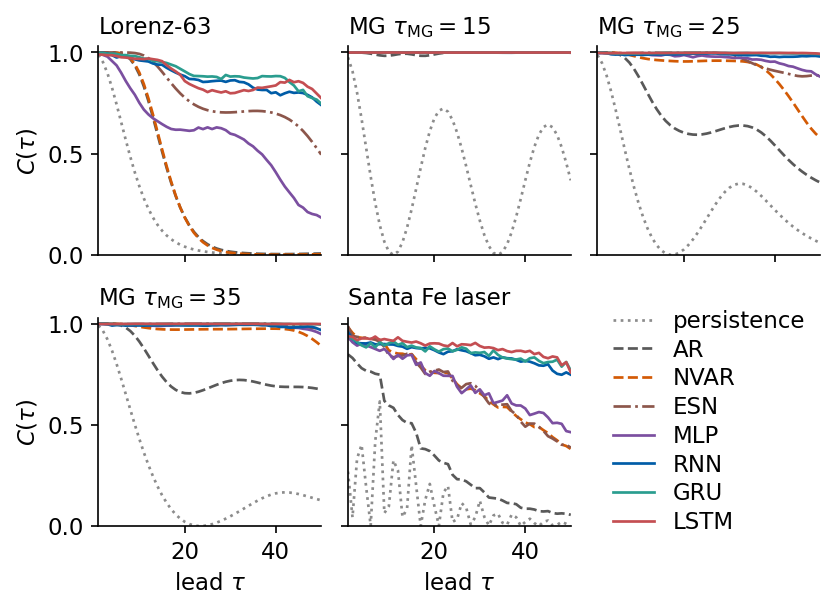

In [32]:
ALL = ("persistence", "AR", "NVAR", "ESN", "MLP", "RNN", "GRU", "LSTM")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 3, figsize=(5.5, 3.9), sharex=True, sharey=True)
    fig.subplots_adjust(left=0.11, right=0.985, bottom=0.12, top=0.94, wspace=0.12, hspace=0.3)
    for ax, name in zip(axs.ravel(), SIGNALS):
        for m in ALL:
            ax.plot(TAUS, res[name][m]["C"], lw=1.3, label=m, **STYLE[m])
        ax.set_title(LABEL[name], loc="left", fontsize=11)
        ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX)
    for ax in axs[1]: ax.set_xlabel(r"lead $\tau$")
    for ax in axs[:, 0]: ax.set_ylabel(r"$C(\tau)$")
    axs[1, 2].axis("off")
    h_, l_ = axs[0, 0].get_legend_handles_labels()
    axs[1, 2].legend(h_, l_, loc="center", ncol=1, handlelength=1.8, labelspacing=0.25, borderaxespad=0)
    save(fig, "fig_capacity_all_models"); plt.show()

print(f"{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (C_tot, maximum 50)")
for m in ALL:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (tau_1/2, '>50' if C stays above 0.5)")
for m in ALL:
    print(f"{m:12s}" + "".join(f"{(res[n][m]['tau_half'] or '>50'):>10}" for n in SIGNALS))
print(f"\n{'model':12s}" + "".join(f"{n:>10s}" for n in SIGNALS) + "     (NMSE at tau = 10)")
for m in ALL:
    print(f"{m:12s}" + "".join(f"{res[n][m]['nmse'][9]:10.3f}" for n in SIGNALS))
nums["Ctot"] = {n: {m: float(res[n][m]["Ctot"]) for m in ALL} for n in SIGNALS}
nums["tau_half"] = {n: {m: res[n][m]["tau_half"] for m in ALL} for n in SIGNALS}
nums["nmse_tau10"] = {n: {m: float(res[n][m]["nmse"][9]) for m in ALL} for n in SIGNALS}
nums["C_tau"] = {n: {m: {t: float(res[n][m]["C"][t - 1]) for t in (1, 5, 10, 25, 50)} for m in ALL} for n in SIGNALS}
nums["ridge_choice"] = {n: {m: dict(p=res[n][m]["p"], beta=res[n][m]["beta"], n_feat=res[n][m]["n_feat"]) for m in ("AR", "NVAR")} for n in SIGNALS}
nums["esn_choice"] = {n: {k: res[n]["ESN"][k] for k in ("rho", "sigma_in", "alpha", "beta")} for n in SIGNALS}

# LaTeX table of C_tot, best value of each column in bold
COLHEAD = {"Lorenz": "Lorenz", "MG15": r"MG $15$", "MG25": r"MG $25$", "MG35": r"MG $35$", "SantaFe": "Santa Fe"}
lines = [r"\begin{tabular}{l" + "c" * len(SIGNALS) + "}", r"\toprule",
         "model & " + " & ".join(COLHEAD[n] for n in SIGNALS) + r" \\", r"\midrule"]
best = {n: max(res[n][m]["Ctot"] for m in ALL) for n in SIGNALS}
for m in ALL:
    cells_ = [(r"\textbf{%.1f}" if round(res[n][m]["Ctot"], 1) == round(best[n], 1) else "%.1f") % res[n][m]["Ctot"] for n in SIGNALS]
    lines.append(f"{m} & " + " & ".join(cells_) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}"]
with open(f"{OUT}/table_lab036_ctot.tex", "w") as fh:
    fh.write("\n".join(lines) + "\n")

### One-step forecasts of the networks and the reservoir

As in the notebook on linear models for AR, MA, ARMA and NVAR, we look at the forecast one step ahead, $\tau=1$, on Santa Fe and on Mackey–Glass at the three delays. For each model the upper panels show the target $s_{k+1}$ (black) and the forecast $\hat s_{k+1}$ (dashed) on the first 100 test targets, and the lower panels show $\hat s_{k+1}$ against $s_{k+1}$ on all test targets, with $C$ and the NMSE at $\tau=1$.

model                 Santa Fe                   MG 15                   MG 25                   MG 35   (C and NMSE at tau = 1)
MLP      C=0.9336 NMSE=6.7e-02   C=0.9998 NMSE=2.2e-04   C=0.9971 NMSE=3.0e-03   C=0.9985 NMSE=2.5e-03
RNN      C=0.9588 NMSE=4.3e-02   C=0.9998 NMSE=2.2e-04   C=0.9977 NMSE=2.4e-03   C=0.9988 NMSE=1.2e-03
GRU      C=0.9388 NMSE=6.2e-02   C=0.9997 NMSE=3.3e-04   C=0.9983 NMSE=1.8e-03   C=0.9991 NMSE=9.2e-04
LSTM     C=0.9375 NMSE=6.3e-02   C=0.9995 NMSE=6.3e-04   C=0.9979 NMSE=2.2e-03   C=0.9984 NMSE=1.7e-03
ESN      C=0.9870 NMSE=1.3e-02   C=1.0000 NMSE=1.7e-10   C=0.9999 NMSE=6.2e-05   C=1.0000 NMSE=2.3e-05


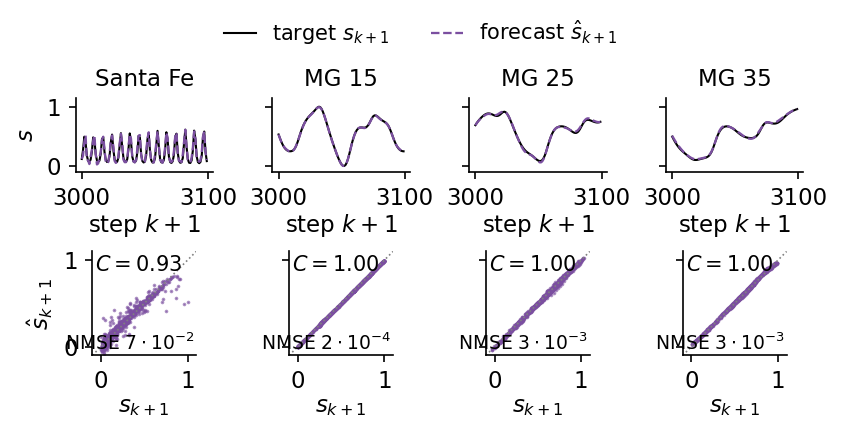

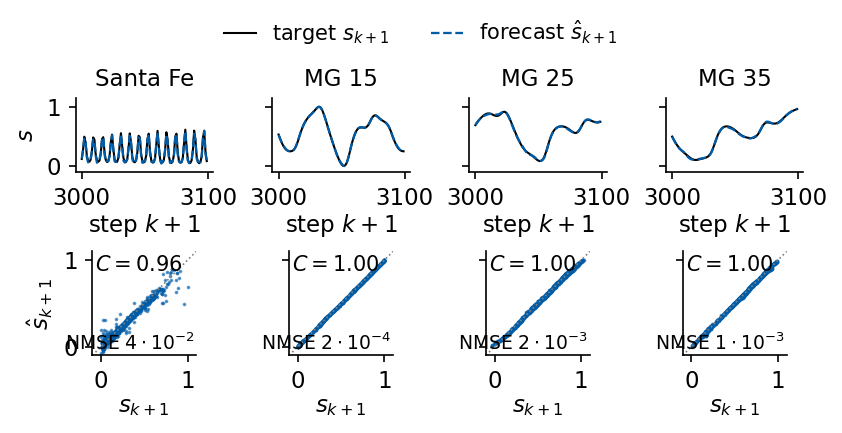

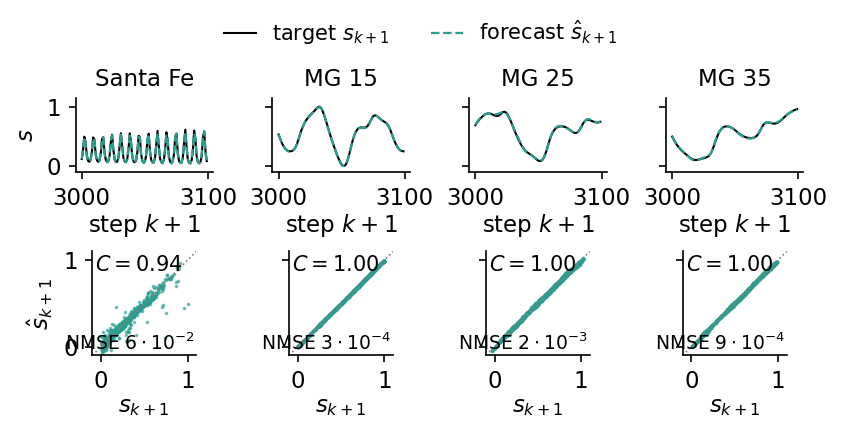

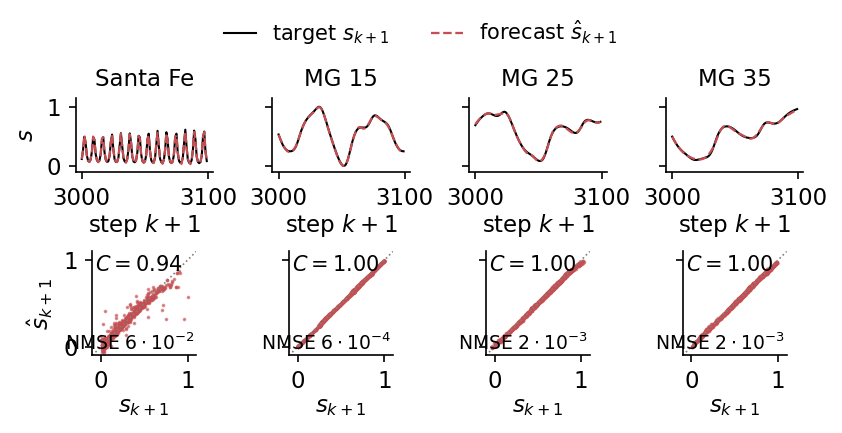

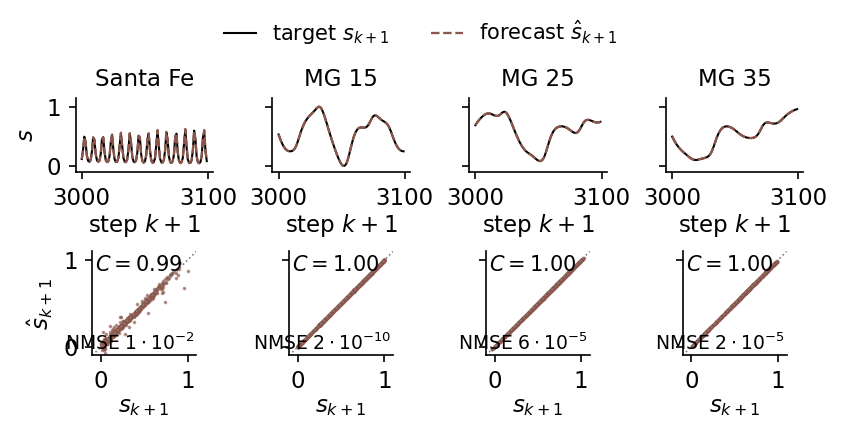

In [33]:
OS_SIG = ["SantaFe", "MG15", "MG25", "MG35"]
OS_TITLE = {"SantaFe": "Santa Fe", "MG15": "MG 15", "MG25": "MG 25", "MG35": "MG 35"}
K_SHOW = 100
nums["one_step"] = {}
for m in ("MLP", "RNN", "GRU", "LSTM", "ESN"):
    col = STYLE[m].get("color", UJBlue)
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(2, 4, figsize=(5.5, 2.8), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
        for c_, name in enumerate(OS_SIG):
            a_t, a_s = axs[0, c_], axs[1, c_]
            y_t = np.asarray(data[name][5], np.float64)[:, 0]
            y_p = np.asarray(res[name][m]["pred"], np.float64)[:, 0]
            Cv = float(np.corrcoef(y_p, y_t)[0, 1] ** 2)
            Nv = float(np.sum((y_t - y_p) ** 2) / np.sum((y_t - y_t.mean()) ** 2))
            nums["one_step"][f"{m} {name}"] = {"C": Cv, "nmse": Nv}
            kk = K_TEST[:K_SHOW] + 1
            a_t.plot(kk, y_t[:K_SHOW], color="k", lw=1.0, label="target $s_{k+1}$")
            a_t.plot(kk, y_p[:K_SHOW], "--", color=col, lw=1.1, label=r"forecast $\hat s_{k+1}$")
            a_t.set_title(OS_TITLE[name]); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
            a_t.set_xticks([kk[0], kk[0] + 100]); a_t.set_xlabel("step $k+1$", labelpad=1)
            a_s.plot(y_t, y_p, ".", ms=1.5, color=col, alpha=0.6)
            a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
            a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
            a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel("$s_{k+1}$", labelpad=1)
            mant, ex = f"{Nv:.0e}".split("e")
            a_s.text(0.03, 0.97, f"$C={Cv:.2f}$", transform=a_s.transAxes, va="top", ha="left", fontsize=10)
            a_s.text(0.98, 0.02, f"NMSE ${mant}\\cdot10^{{{int(ex)}}}$", transform=a_s.transAxes, va="bottom", ha="right", fontsize=9)
            if c_ > 0:
                a_t.set_yticklabels([]); a_s.set_yticklabels([])
        axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+1}$")
        fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=10, handlelength=1.5)
        save(fig, f"fig_onestep_{m.lower()}"); plt.show()
print(f"{'model':6s}" + "".join(f"{OS_TITLE[n]:>24s}" for n in OS_SIG) + "   (C and NMSE at tau = 1)")
for m in ("MLP", "RNN", "GRU", "LSTM", "ESN"):
    print(f"{m:6s}" + "".join(f"   C={nums['one_step'][f'{m} {n}']['C']:.4f} NMSE={nums['one_step'][f'{m} {n}']['nmse']:.1e}" for n in OS_SIG))

<hr/>
### Static models against recurrent networks

We compare the capacity curves of the static models of the notebook on linear models, which see a fixed window of past values (AR, MA, NVAR), with the two recurrent networks of this lecture (RNN, LSTM) on Santa Fe and on Mackey–Glass in its three regimes. AR and NVAR are the models fitted in Section 2. For MA we fit an MA(8) model by maximum likelihood on the training block and forecast with the one-step prediction errors $e_k=s_k-\hat s_k$ of the fitted model,
$$
\hat s_{k+\tau}=\mu+\sum_{j=\tau}^{q}\theta_j\,e_{k+\tau-j},
$$
so the MA forecast returns to the mean $\mu$ after $q=8$ steps and its capacity drops to zero there.

The MA order is fixed at q=8 for this comparison. Its parameters are fitted on the first 2500 samples, the same fitting block used by the other models. Filtering the later observations updates past innovations at each origin without refitting parameters or using observations beyond that origin.

SantaFe  MA(8): C(1) = 0.7733, C(8) = 0.407, C_tot = 4.7
MG15     MA(8): C(1) = 1.0000, C(8) = 0.593, C_tot = 7.1
MG25     MA(8): C(1) = 1.0000, C(8) = 0.674, C_tot = 7.2
MG35     MA(8): C(1) = 1.0000, C(8) = 0.733, C_tot = 7.4
model          SantaFe      MG15      MG25      MG35     (C_tot, maximum 50)
persistence        5.5      19.5      13.3      11.8
AR                16.5      49.8      33.1      38.0
MA                 4.7       7.1       7.2       7.4
NVAR              34.7      50.0      45.5      48.6
RNN               42.5      50.0      49.4      49.5
LSTM              44.3      50.0      49.9      49.9


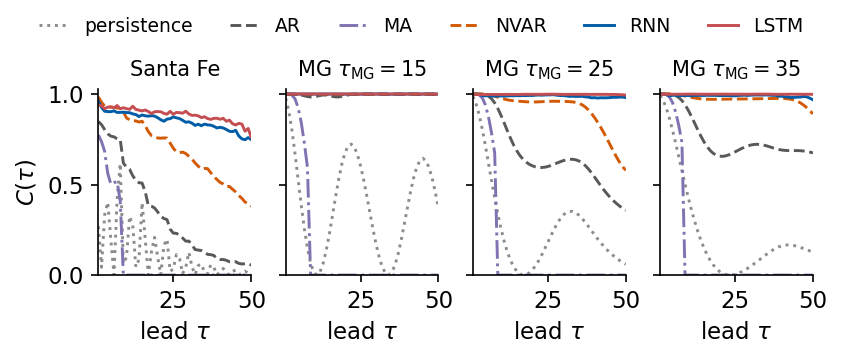

In [34]:
CMP_SIG = ["SantaFe", "MG15", "MG25", "MG35"]
CMP = ("persistence", "AR", "MA", "NVAR", "RNN", "LSTM")
STYLE["MA"] = dict(color="#8172B2", ls="-.")
Q_MA = 8
for name in CMP_SIG:
    s = sig[name]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        fit_ma = ARIMA(s[:N_TRAIN - N_VAL], order=(0, 0, Q_MA), trend="c").fit(method_kwargs={"maxiter": 300})
        e = np.asarray(fit_ma.apply(s).resid)                      # causal filtered one-step errors; fixed parameters, no refitting on later values
    mu, theta = float(fit_ma.params[0]), np.asarray(fit_ma.params[1:1 + Q_MA])
    pred = np.full((len(K_TEST), TAU_MAX), mu)
    for t in range(1, Q_MA + 1):                                   # beyond tau = q the forecast is the mean
        for jj in range(t, Q_MA + 1):
            pred[:, t - 1] += theta[jj - 1] * e[K_TEST + t - jj]
    res[name]["MA"] = dict(pred=pred, **score(pred, np.asarray(data[name][5], np.float64)))
    print(f"{name:8s} MA({Q_MA}): C(1) = {res[name]['MA']['C'][0]:.4f}, C({Q_MA}) = {res[name]['MA']['C'][Q_MA - 1]:.3f},"
          f" C_tot = {res[name]['MA']['Ctot']:.1f}")

TITLE_CMP = {"SantaFe": "Santa Fe", "MG15": r"MG $\tau_{\rm MG}=15$", "MG25": r"MG $\tau_{\rm MG}=25$", "MG35": r"MG $\tau_{\rm MG}=35$"}
def capacity_panel(ax, name):
    for m in CMP:
        ax.plot(TAUS, res[name][m]["C"], lw=1.4, label=m, **STYLE[m])
    ax.set_ylim(0, 1.03); ax.set_xlim(1, TAU_MAX); ax.set_xlabel(r"lead $\tau$")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 4, figsize=(5.5, 2.3), layout="constrained", sharey=True)
    for ax, name in zip(axs, CMP_SIG):
        capacity_panel(ax, name); ax.set_title(TITLE_CMP[name], fontsize=10)
    axs[0].set_ylabel(r"$C(\tau)$")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=6, fontsize=9, handlelength=1.6)
    save(fig, "fig_capacity_compare"); plt.show()
for name in CMP_SIG:
    with mpl.rc_context(SLIDE_RC):
        fig, ax = plt.subplots(figsize=(4.4, 2.5), layout="constrained")
        capacity_panel(ax, name); ax.set_ylabel(r"$C(\tau)$")
        ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9, ncol=1, handlelength=1.8, frameon=False)
        save(fig, f"fig_capacity_cmp_{name}"); plt.close(fig)
print(f"{'model':12s}" + "".join(f"{n:>10s}" for n in CMP_SIG) + "     (C_tot, maximum 50)")
for m in CMP:
    print(f"{m:12s}" + "".join(f"{res[n][m]['Ctot']:10.1f}" for n in CMP_SIG))
nums["Ctot_compare"] = {n: {m: float(res[n][m]["Ctot"]) for m in CMP} for n in CMP_SIG}

### Forecasts of the laser at several leads

The capacity curve summarises each lead by one number. We also show the forecasts of the Santa Fe laser at the leads $\tau=1,2,5,10$ for each model. The upper panels show the target $s_{k+\tau}$ (black) and the forecast $\hat s_{k+\tau}$ (dashed) on the first 100 test steps, the lower panels the forecast against the target on all test steps.

Santa Fe C(tau) at tau = 1, 2, 5, 10
AR       0.848   0.830   0.767   0.596
MA       0.773   0.737   0.501   0.000
NVAR     0.983   0.954   0.928   0.868
RNN      0.959   0.925   0.902   0.897
LSTM     0.937   0.934   0.928   0.919


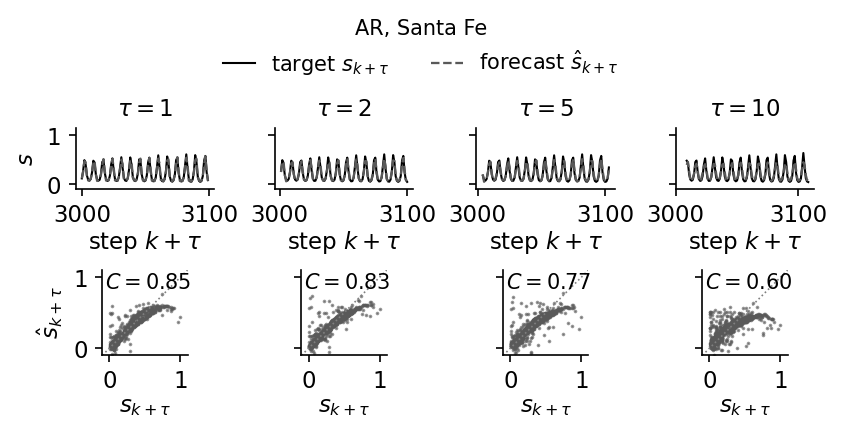

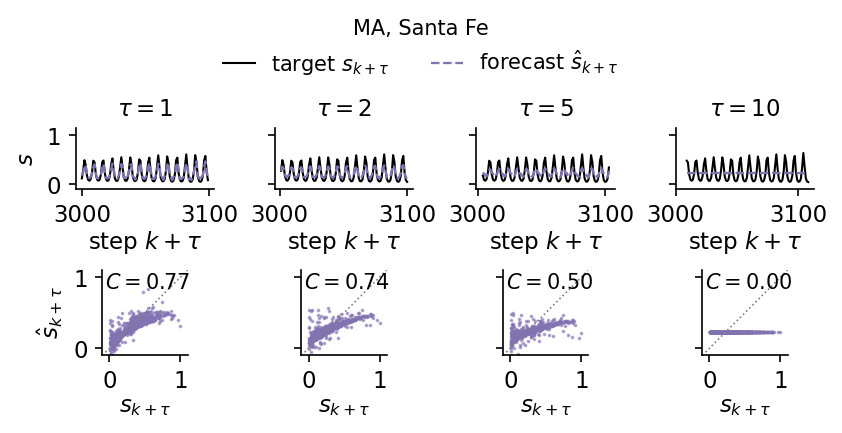

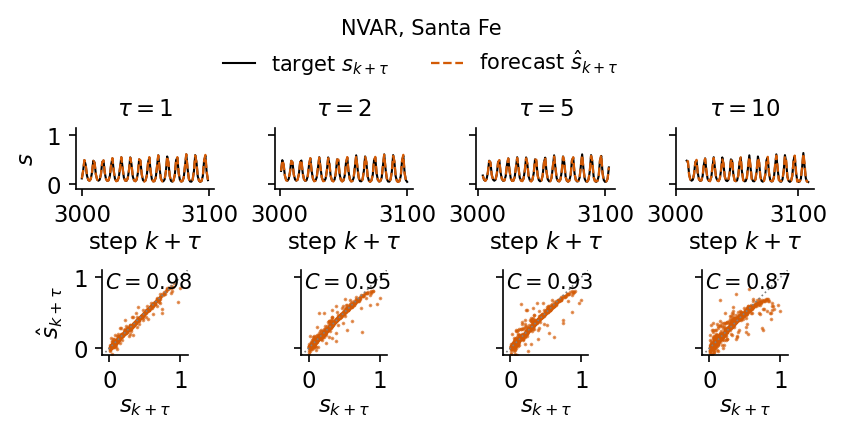

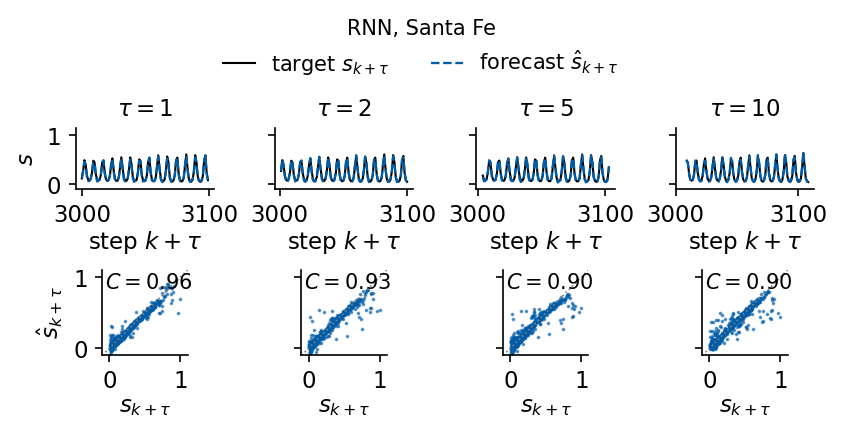

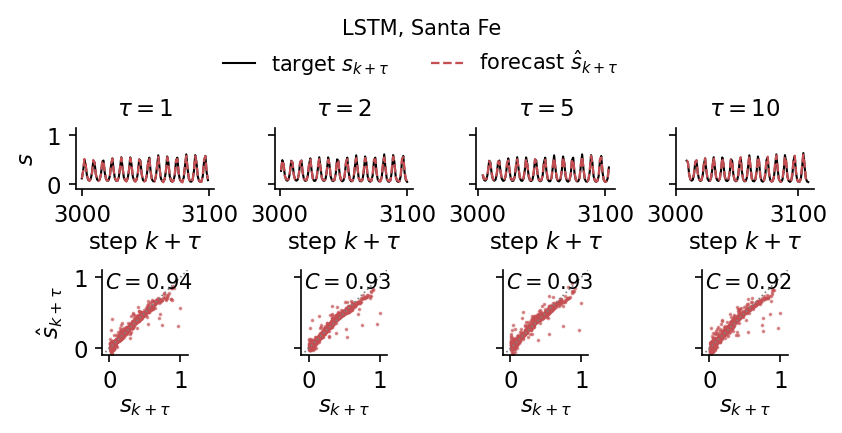

In [35]:
TAU_SHOW = (1, 2, 5, 10)
Yt_sf_all = np.asarray(data["SantaFe"][5], np.float64)
nums["santafe_leads"] = {}
for m in ("AR", "MA", "NVAR", "RNN", "LSTM"):
    col = STYLE[m].get("color", UJBlue)
    P = np.asarray(res["SantaFe"][m]["pred"], np.float64)
    with mpl.rc_context(SLIDE_RC):
        fig, axs = plt.subplots(2, 4, figsize=(5.5, 2.8), layout="constrained", gridspec_kw={"height_ratios": [1.0, 1.4]})
        for c_, t in enumerate(TAU_SHOW):
            a_t, a_s = axs[0, c_], axs[1, c_]
            y_t, y_p = Yt_sf_all[:, t - 1], P[:, t - 1]
            Cv = float(np.corrcoef(y_p, y_t)[0, 1] ** 2) if y_p.std() > 0 else 0.0
            nums["santafe_leads"][f"{m} {t}"] = Cv
            kk = K_TEST[:K_SHOW] + t
            a_t.plot(kk, y_t[:K_SHOW], color="k", lw=1.0, label=r"target $s_{k+\tau}$")
            a_t.plot(kk, y_p[:K_SHOW], "--", color=col, lw=1.1, label=r"forecast $\hat s_{k+\tau}$")
            a_t.set_title(rf"$\tau={t}$"); a_t.set_ylim(-0.1, 1.15); a_t.set_yticks([0, 1])
            a_t.set_xticks([3000, 3100]); a_t.set_xlabel(r"step $k+\tau$", labelpad=1)
            a_s.plot(y_t, y_p, ".", ms=1.5, color=col, alpha=0.6)
            a_s.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.8, ls=":")
            a_s.set_xlim(-0.1, 1.1); a_s.set_ylim(-0.1, 1.1); a_s.set_aspect("equal")
            a_s.set_xticks([0, 1]); a_s.set_yticks([0, 1]); a_s.set_xlabel(r"$s_{k+\tau}$", labelpad=1)
            a_s.text(0.03, 0.97, f"$C={Cv:.2f}$", transform=a_s.transAxes, va="top", ha="left", fontsize=10)
            if c_ > 0:
                a_t.set_yticklabels([]); a_s.set_yticklabels([])
        axs[0, 0].set_ylabel("$s$"); axs[1, 0].set_ylabel(r"$\hat s_{k+\tau}$")
        fig.legend(*axs[0, 0].get_legend_handles_labels(), loc="outside upper center", ncol=2, fontsize=10, handlelength=1.5,
                   title=f"{m}, Santa Fe", title_fontsize=10)
        save(fig, f"fig_santafe_leads_{m.lower()}"); plt.show()
print("Santa Fe C(tau) at tau = 1, 2, 5, 10")
for m in ("AR", "MA", "NVAR", "RNN", "LSTM"):
    print(f"{m:6s}" + "".join(f"{nums['santafe_leads'][f'{m} {t}']:8.3f}" for t in TAU_SHOW))

A grid of panels collects all five models, with the models in rows and the leads in columns, and each panel shows the forecast against the target on the Santa Fe test block.

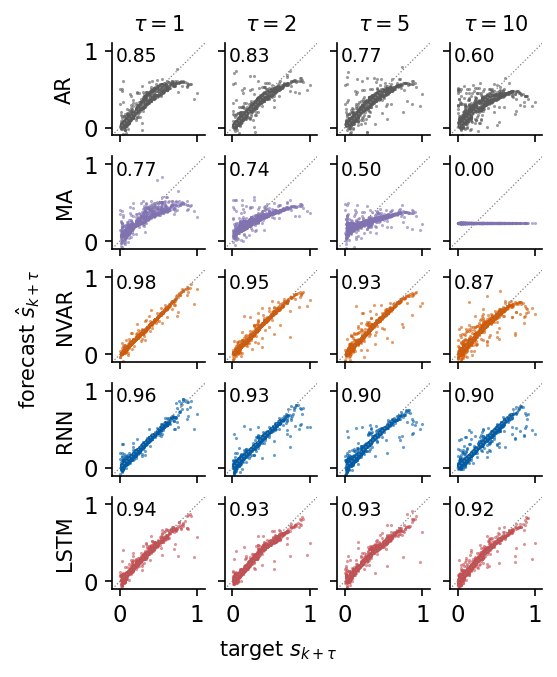

In [36]:
GRID_M = ("AR", "MA", "NVAR", "RNN", "LSTM")
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(len(GRID_M), len(TAU_SHOW), figsize=(3.6, 4.4), layout="constrained", sharex=True, sharey=True)
    for r_, m in enumerate(GRID_M):
        P = np.asarray(res["SantaFe"][m]["pred"], np.float64)
        col = STYLE[m].get("color", UJBlue)
        for c_, t in enumerate(TAU_SHOW):
            ax = axs[r_, c_]
            ax.plot(Yt_sf_all[:, t - 1], P[:, t - 1], ".", ms=1.0, color=col, alpha=0.6)
            ax.plot([-0.1, 1.1], [-0.1, 1.1], color="0.5", lw=0.6, ls=":")
            ax.set_xlim(-0.1, 1.1); ax.set_ylim(-0.1, 1.1); ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
            ax.text(0.04, 0.96, f"{nums['santafe_leads'][f'{m} {t}']:.2f}", transform=ax.transAxes, va="top", ha="left", fontsize=9)
            if r_ == 0:
                ax.set_title(rf"$\tau={t}$", fontsize=10)
        axs[r_, 0].set_ylabel(m, fontsize=10)
    fig.supxlabel(r"target $s_{k+\tau}$", fontsize=10); fig.supylabel(r"forecast $\hat s_{k+\tau}$", fontsize=10)
    save(fig, "fig_santafe_scatter_grid"); plt.show()

The comparison follows the characterisation of the signals in the signals notebook. The limit cycle of Mackey–Glass at $\tau_{\rm MG}=15$ is predictable by every model with a window of past values. The linear AR model reaches $C_{\rm tot}=49.8$ and all nonlinear models 50.0, while persistence oscillates with the period of the cycle. A periodic signal needs no nonlinear features.

The chaotic Mackey–Glass signals separate linear from nonlinear models. AR reaches 33.1 at $\tau_{\rm MG}=25$ and 38.0 at $\tau_{\rm MG}=35$. NVAR raises this to 45.5 and 48.6, and the ESN and all trained networks reach between 48.3 and 49.9, with $C(50)$ between 0.88 and 0.998. The delay equation has a one-dimensional input and a smooth nonlinearity, and a window that covers the delay already contains what the forecast needs, so the ESN and the trained networks differ by less than two units here.

The Lorenz signal separates the models with a fixed window from those with a learned state. AR and NVAR give the same value, 15.4, with $\tau_{1/2}=16$. The flow is symmetric under $(x,y,z)\to(-x,-y,z)$, so the future of the first coordinate is an odd function of its past. Quadratic monomials are even under this symmetry, which is consistent with NVAR giving no gain (the rescaling to $[0,1]$ shifts the centre of the symmetry approximately to 0.5, and the linear terms and the intercept absorb this shift). The ESN reaches 39.2, the MLP 29.4, and the RNN, GRU and LSTM 43.8, 45.1 and 43.8 with $C(\tau)>0.5$ up to the last lead, which corresponds to one time unit of the Lorenz flow. The odd nonlinear functions that the forecast needs are available to tanh networks and reservoirs, and the recurrent networks learn them best among the models tested.

The Santa Fe laser, whose large pulses fold the reconstructed attractor, separates the models most strongly. AR reaches 16.5, NVAR 34.7, ESN 34.7, MLP 35.3, and the recurrent networks 42.5 (RNN), 43.0 (GRU) and 44.3 (LSTM). The MLP and recurrent networks read 64 past values. NVAR selects a shorter feature window, the ESN carries a continuously driven state, and the trained LSTM uses memory times of a few steps. The advantage of the recurrent networks here therefore comes from the nonlinear processing of the recent window, which the recurrence learns better than a fixed list of monomials, a fixed random reservoir, or a single tanh layer of 64 units. The validation search chose $\rho=1.1$ for the ESN on Lorenz and on Mackey–Glass at $\tau_{\rm MG}=15$. It does not test the echo state property, which our direct test in Section 4 found violated at $\rho=1.2$ for the Santa Fe input, so these two ESN results come from reservoirs whose dependence on the initial state was not checked. These statements hold for one fixed-size setting of each model, chosen without a separate search for each signal, and with one seed for all signals but Santa Fe.

The LSTM forecast on Santa Fe degrades with the lead, as the scatter of true against predicted values shows.

Santa Fe LSTM: C(1), C(5), C(10) = [0.937 0.928 0.919] | NMSE = [0.063 0.072 0.081]


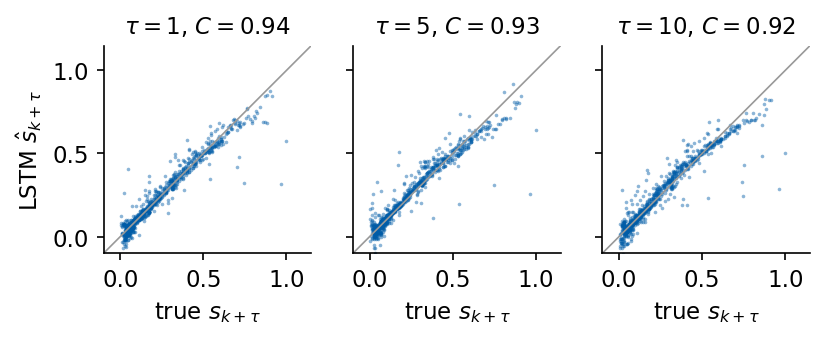

In [37]:
P_lstm = res["SantaFe"]["LSTM"]["pred"]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.15), sharey=True, layout="constrained")
    for ax, t in zip(axs, (1, 5, 10)):
        scatter_panel(ax, Yt_sf[:, t - 1], P_lstm[:, t - 1], rf"$\tau={t}$, $C={res['SantaFe']['LSTM']['C'][t - 1]:.2f}$")
        ax.set_xlabel(r"true $s_{k+\tau}$")
    axs[0].set_ylabel(r"LSTM $\hat s_{k+\tau}$")
    save(fig, "fig_santafe_scatter_lstm"); plt.show()
print("Santa Fe LSTM: C(1), C(5), C(10) =", np.round(res["SantaFe"]["LSTM"]["C"][[0, 4, 9]], 3),
      "| NMSE =", np.round(res["SantaFe"]["LSTM"]["nmse"][[0, 4, 9]], 3))

### Cost

The ridge models and the ESN are fitted by one linear solve, the networks by many passes of gradient descent through the unrolled sequence. The fit times are wall-clock times on the processor used for these runs, for the selected setting only and without the hyperparameter search, and they change with hardware and implementation.

In [38]:
cost = {}
for m in ("AR", "NVAR", "ESN"):
    cost[m] = float(np.median([res[n][m]["t_fit"] for n in SIGNALS]))
for m in MODELS:
    cost[m] = float(np.median([res[n][m]["time"] for n in SIGNALS]))
nums["fit_time_median_s"] = cost
for m, t in cost.items():
    extra = f"{res['SantaFe'][m]['n_feat']} features" if m in ("AR", "NVAR") else (
        f"{N_ESN} reservoir units" if m == "ESN" else f"{res['SantaFe'][m]['n_params']} parameters")
    print(f"{m:5s} median fit time over the 5 signals {t:8.3f} s  ({extra} on Santa Fe)")

AR    median fit time over the 5 signals    0.003 s  (64 features on Santa Fe)
NVAR  median fit time over the 5 signals    0.047 s  (560 features on Santa Fe)
ESN   median fit time over the 5 signals    0.089 s  (300 reservoir units on Santa Fe)
MLP   median fit time over the 5 signals    2.220 s  (7410 parameters on Santa Fe)
RNN   median fit time over the 5 signals   13.158 s  (2738 parameters on Santa Fe)
GRU   median fit time over the 5 signals   50.918 s  (4914 parameters on Santa Fe)
LSTM  median fit time over the 5 signals   54.711 s  (6002 parameters on Santa Fe)


In this recorded run the median fitting times over the five signals are about 3 ms for AR, 0.047 s for NVAR and 0.089 s for the ESN, including the reservoir run. The network medians are 2.2 s (MLP), 13 s (RNN), 51 s (GRU) and 55 s (LSTM), so here a gated-network fit costs about 600 times the ESN fit. These wall times depend on hardware and concurrent system load. Ridge regression solves one linear system, while backpropagation through time runs every training window forward and backward through all $L$ steps of the recurrence, for several hundred epochs. The whole ESN search over 24 reservoirs and 4 ridge strengths took about 20 s for all five signals in this recorded run, less than the training of two gated networks. For the Mackey–Glass signals the ESN comes within two units of $C_{\rm tot}$ of the best network, and the extra cost of the gated networks gives a higher capacity on Santa Fe and Lorenz.
<hr/>
## 10. Free run and exposure bias

We trained and tested all models with the true past as input. During training a recurrent network is always fed measured values, which is called teacher forcing. A model that generates a signal must instead feed its own predictions back as inputs. Its errors then enter the input, a situation it has never seen in training, and they can grow. This mismatch between training and use is called exposure bias.

We test it on the Santa Fe laser. Every model predicts one step ahead with its $\tau=1$ output, the prediction is appended to the window (for the ESN it drives the reservoir), and the procedure is repeated for 200 steps from the origin $k_0=2999$, the last sample of the training block. We measure the error of the free run by the NMSE over the first 50 and 200 steps and by the number of steps before the error $|\hat s_{k_0+j}-s_{k_0+j}|$ first exceeds 0.2, a fifth of the training range.

AR    free run: NMSE over 50 steps    0.239, over 200 steps    0.852, error below 0.2 for the first 38 steps
NVAR  free run: NMSE over 50 steps    0.427, over 200 steps 1638.748, error below 0.2 for the first 36 steps
ESN   free run: NMSE over 50 steps    0.155, over 200 steps 1658.507, error below 0.2 for the first 47 steps
MLP   free run: NMSE over 50 steps    0.932, over 200 steps    1.519, error below 0.2 for the first 9 steps
RNN   free run: NMSE over 50 steps    0.556, over 200 steps    1.832, error below 0.2 for the first 23 steps
GRU   free run: NMSE over 50 steps    0.374, over 200 steps    0.997, error below 0.2 for the first 38 steps
LSTM  free run: NMSE over 50 steps    0.007, over 200 steps    1.094, error below 0.2 for the first 110 steps


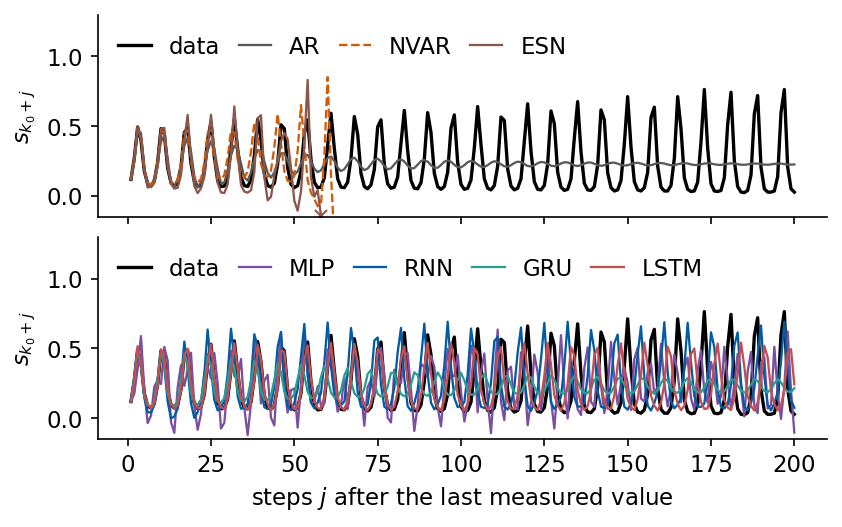

In [39]:
N_FREE, K0 = 200, N_TRAIN - 1
s_sf = sig["SantaFe"]
truth = s_sf[K0 + 1:K0 + 1 + N_FREE]

def free_run_window(one_step, s, k0, n_steps, L):
    # one_step(window of the last L values) -> next value; the prediction is appended to the window
    buf = list(s[k0 - L + 1:k0 + 1])
    out = []
    for _ in range(n_steps):
        y = float(one_step(np.asarray(buf[-L:])))
        y = float(np.clip(y, -10, 10))              # keeps a diverging model finite
        out.append(y); buf.append(y)
    return np.array(out)

def ridge_one_step(m):
    feats, p = FEATS[m], res["SantaFe"][m]["p"]
    W1, b1 = res["SantaFe"][m]["W"][:, 0], res["SantaFe"][m]["b"][0]
    return lambda w: feats(w, np.array([len(w) - 1]), p)[0] @ W1 + b1

def net_one_step(model):
    f = jax.jit(lambda w: model(w[None, :, None].astype(jnp.float32))[0, 0])
    return lambda w: f(jnp.asarray(w))

def esn_free_run(e, s, k0, n_steps):
    # state at k0 from the true inputs, then the tau = 1 output drives the reservoir
    W, w_in, a = e["rho"] * W_esn, e["sigma_in"] * w_esn, e["alpha"]
    Wo, b = jnp.asarray(e["W_out"][:, 0]), e["b"][0]
    def step(x, _):
        y = jnp.clip(x @ Wo + b, -10, 10)
        x = (1 - a) * x + a * jnp.tanh(W @ x + w_in * y)
        return x, y
    return np.asarray(jax.lax.scan(step, jnp.asarray(e["X"][k0]), None, length=n_steps)[1])

free = {"AR": free_run_window(ridge_one_step("AR"), s_sf, K0, N_FREE, 64),
        "NVAR": free_run_window(ridge_one_step("NVAR"), s_sf, K0, N_FREE, 64),
        "ESN": esn_free_run(res["SantaFe"]["ESN"], s_sf, K0, N_FREE)}
for m in MODELS:
    free[m] = free_run_window(net_one_step(nets["SantaFe"][m]), s_sf, K0, N_FREE, L_WIN)

nums["freerun"] = {}
for m, y in free.items():
    err = np.abs(y - truth)
    t_valid = int(np.argmax(err > 0.2)) if (err > 0.2).any() else N_FREE
    nums["freerun"][m] = dict(nmse50=nmse(y[:50], truth[:50]), nmse200=nmse(y, truth), steps_below_0p2=t_valid)
    print(f"{m:5s} free run: NMSE over 50 steps {nmse(y[:50], truth[:50]):8.3f}, over 200 steps {nmse(y, truth):8.3f},"
          f" error below 0.2 for the first {t_valid} steps")

with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 3.4), sharex=True, layout="constrained")
    j = np.arange(1, N_FREE + 1)
    for ax, group in zip(axs, (("AR", "NVAR", "ESN"), ("MLP", "RNN", "GRU", "LSTM"))):
        ax.plot(j, truth, color="k", lw=1.6, label="data")
        for m in group:
            y = free[m].copy()
            out = np.nonzero(np.abs(y - 0.5) > 1.0)[0]
            if len(out):
                y[out[0]:] = np.nan                   # stop drawing once the run leaves [-0.5, 1.5]
                ax.plot(j[out[0] - 1], free[m][out[0] - 1], "x", color=STYLE[m]["color"], ms=6)
            ax.plot(j, y, lw=1.1, label=m, color=STYLE[m]["color"], ls="-" if m != "NVAR" else "--")
        ax.set_ylim(-0.15, 1.3); ax.set_ylabel(r"$s_{k_0+j}$")
        ax.legend(loc="upper left", ncol=5, handlelength=1.4, columnspacing=0.8)
    axs[1].set_xlabel(r"steps $j$ after the last measured value")
    save(fig, "fig_freerun_networks"); plt.show()

The free run separates the models differently from the direct forecasts. The linear AR model relaxes within about 50 steps to a small regular oscillation around the mean, the behaviour of a stable linear system. NVAR and the ESN follow the pulses for some 40 to 60 steps and then diverge, because their feedback loop through the quadratic features or the reservoir is unstable (the crosses mark where the curves leave the plotted range). The MLP keeps oscillating but with distorted pulses, and its error exceeds 0.2 after 9 steps. The LSTM stays close to the data for 110 steps, with NMSE 0.007 over the first 50 steps, and then keeps pulsating with a smaller amplitude and a drifting phase. The RNN and the GRU leave the data after 23 and 38 steps, the GRU settling to a small oscillation. Over 200 steps no model reproduces the data, and the NMSE values are around 1 or larger, the level of a forecast that has lost the phase.

The networks were trained only on true past values, with teacher forcing. A model that is good at one-step prediction need not produce a good free run, because its own errors move the input away from the data it was trained on. These results come from one origin and one seed. Free runs of chaotic signals amplify small differences between models, so the ranking of the free runs is far less robust than the ranking of the direct forecasts. Training on the model's own predictions, or on noisy inputs, is the usual remedy for this exposure bias.

<hr/>
## Model dependence of forecasting accuracy

We compared models of increasing flexibility on five signals at the same chronological test origins and leads $\tau=1,\dots,50$, scored by $C(\tau)=r^2$ and $C_{\rm tot}$. The neural models use 64-value windows, AR and NVAR select their feature lengths, MA uses causally filtered innovations, and the ESN uses its continuously driven reservoir state. Ridge and neural models forecast the leads directly, while MA follows its fitted stochastic model. Linear AR suffices for the limit cycle of Mackey–Glass at $\tau_{\rm MG}=15$. The chaotic signals need nonlinear features, and the folding pulses of the Santa Fe laser show the largest differences between models.

An MLP on the window learns its features instead of using the fixed monomials of NVAR. The echo state network keeps the history in a fixed random dynamical system and trains only a ridge readout. It forgets its initial state when the spectral radius is small enough, which we tested directly, it has a linear memory capacity of up to 20 for 50 units, and it solves the NARMA-2 and NARMA-5 tasks where a linear readout of the inputs fails. The reservoir idea carries over to physical systems such as the soft arm of Nakajima *et al.*

The recurrent neural network trains the recurrence itself. Backpropagation through time multiplies the step Jacobians $D_iW_h$, so gradients vanish for a contracting hidden dynamics and explode for an expanding one, which we measured for random networks. The LSTM and the GRU add gated paths whose direct Jacobians are diagonal products of gate values, so the gates act as learned memory times $-1/\ln f$. We implemented all three cells in `flax.nnx`, checked them against the library cells to round-off precision, and trained them with Adam, gradient clipping and early stopping on rescaled windows. On Santa Fe the order LSTM > GRU > RNN > MLP is stable over three seeds, and the recurrent networks also lead on Lorenz, at a training cost several hundred times that of the reservoir. In free runs on their own predictions all models lose the phase within a few pulsation periods, and the direct forecasts with teacher forcing overestimate how well a model generates the signal.

## References

- J. L. Elman, *Finding structure in time*, Cogn. Sci. **14**, 179 (1990), [doi:10.1207/s15516709cog1402_1](https://doi.org/10.1207/s15516709cog1402_1)
- G. Cybenko, *Approximation by superpositions of a sigmoidal function*, Math. Control Signals Syst. **2**, 303 (1989), [doi:10.1007/BF02551274](https://doi.org/10.1007/BF02551274)
- K. Hornik, *Approximation capabilities of multilayer feedforward networks*, Neural Netw. **4**, 251 (1991), [doi:10.1016/0893-6080(91)90009-T](https://doi.org/10.1016/0893-6080(91)90009-T)
- Y. Bengio, P. Simard, P. Frasconi, *Learning long-term dependencies with gradient descent is difficult*, IEEE Trans. Neural Netw. **5**, 157 (1994), [doi:10.1109/72.279181](https://doi.org/10.1109/72.279181)
- S. Hochreiter, J. Schmidhuber, *Long short-term memory*, Neural Comput. **9**, 1735 (1997), [doi:10.1162/neco.1997.9.8.1735](https://doi.org/10.1162/neco.1997.9.8.1735)
- F. A. Gers, J. Schmidhuber, F. Cummins, *Learning to forget: continual prediction with LSTM*, Neural Comput. **12**, 2451 (2000), [doi:10.1162/089976600300015015](https://doi.org/10.1162/089976600300015015)
- K. Cho *et al.*, *Learning phrase representations using RNN encoder–decoder for statistical machine translation*, EMNLP (2014), [doi:10.3115/v1/D14-1179](https://doi.org/10.3115/v1/D14-1179)
- R. Pascanu, T. Mikolov, Y. Bengio, *On the difficulty of training recurrent neural networks*, ICML (2013), [arXiv:1211.5063](https://arxiv.org/abs/1211.5063)
- H. Jaeger, *The "echo state" approach to analysing and training recurrent neural networks*, GMD Report 148 (2001)
- M. Lukoševičius, H. Jaeger, *Reservoir computing approaches to recurrent neural network training*, Comput. Sci. Rev. **3**, 127 (2009), [doi:10.1016/j.cosrev.2009.03.005](https://doi.org/10.1016/j.cosrev.2009.03.005)
- J. Dambre, D. Verstraeten, B. Schrauwen, S. Massar, *Information processing capacity of dynamical systems*, Sci. Rep. **2**, 514 (2012), [doi:10.1038/srep00514](https://doi.org/10.1038/srep00514)
- K. Nakajima, H. Hauser, T. Li, R. Pfeifer, *Information processing via physical soft body*, Sci. Rep. **5**, 10487 (2015), [doi:10.1038/srep10487](https://doi.org/10.1038/srep10487)
- A. F. Atiya, A. G. Parlos, *New results on recurrent network training: unifying the algorithms and accelerating convergence*, IEEE Trans. Neural Netw. **11**, 697 (2000), [doi:10.1109/72.846741](https://doi.org/10.1109/72.846741)
- D. J. Gauthier, E. Bollt, A. Griffith, W. A. S. Barbosa, *Next generation reservoir computing*, Nat. Commun. **12**, 5564 (2021), [doi:10.1038/s41467-021-25801-2](https://doi.org/10.1038/s41467-021-25801-2)

In [40]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(f"{OUT}/numbers_lab036.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

# LaTeX macros \labthreesix... (letters only) for the numbers the slides use
SIGTAG = {"Lorenz": "Lorenz", "MG15": "MGfifteen", "MG25": "MGtwentyfive", "MG35": "MGthirtyfive", "SantaFe": "SantaFe"}
MODTAG = {"persistence": "Persistence", "AR": "AR", "NVAR": "NVAR", "ESN": "ESN", "MLP": "MLP", "RNN": "RNN", "GRU": "GRU", "LSTM": "LSTM"}
macros = {}
for n in SIGNALS:
    for m in ALL:
        macros[f"Ctot{MODTAG[m]}{SIGTAG[n]}"] = f"{res[n][m]['Ctot']:.1f}"
        th = res[n][m]["tau_half"]
        macros[f"TauHalf{MODTAG[m]}{SIGTAG[n]}"] = str(th) if th else "{>}50"
for t, tag in ((1, "One"), (5, "Five"), (10, "Ten")):
    macros[f"CLSTMSantaFe{tag}"] = f"{res['SantaFe']['LSTM']['C'][t - 1]:.2f}"
for m in ("AR", "NVAR", "MLP"):
    macros[f"CFive{m}SantaFe"] = f"{nums['santafe_C5'][m]:.2f}"
for m in MODELS:
    v = np.array(nums["santafe_seeds_Ctot"][m])
    macros[f"SeedMin{m}"] = f"{v.min():.1f}"; macros[f"SeedMax{m}"] = f"{v.max():.1f}"
    macros[f"Params{m}"] = str(nums["param_counts"][m])
    macros[f"FitTime{m}"] = f"{cost[m]:.0f}"
for m in ("AR", "NVAR", "ESN"):
    macros[f"FitTime{m}"] = f"{1000 * cost[m]:.0f}"           # milliseconds
for m, d in nums["freerun"].items():
    macros[f"FreeSteps{MODTAG[m]}"] = str(d["steps_below_0p2"])
    macros[f"FreeNmseFifty{MODTAG[m]}"] = f"{d['nmse50']:.2f}"
for rho_, tag in ((0.5, "Half"), (1.0, "One"), (1.5, "OneHalf")):
    macros[f"GradRate{tag}"] = f"{nums['gradient_norm_rate'][f'rho_{rho_}']:+.3f}"
for rho_, tag in ((0.5, "Half"), (0.8, "EightTenths"), (0.95, "NinetyFive"), (1.1, "OneTenth")):
    macros[f"MC{tag}"] = f"{nums['memory_capacity'][f'rho_{rho_}']:.1f}"
for n, tag in ((2, "Two"), (5, "Five"), (10, "Ten")):
    for mk, mt in (("linear (20 inputs)", "Linear"), ("NVAR (12 inputs)", "NVAR"), ("ESN (N = 100)", "ESN")):
        macros[f"Narma{tag}{mt}"] = f"{narma_tab[n][mk]:.3f}"
macros["TauMemMedian"] = f"{nums['lstm_santafe_tau_mem']['median']:.1f}"
macros["TauMemMax"] = f"{nums['lstm_santafe_tau_mem']['max']:.1f}"
macros["SatRaw"] = f"{nums['saturation']['raw intensity']:.2f}"
macros["SatScaled"] = f"{nums['saturation']['rescaled to [0, 1]']:.2f}"
for k, v in nums["santafe_leads"].items():
    m, t = k.split()
    macros[f"LeadC{m}{ {'1': 'One', '2': 'Two', '5': 'Five', '10': 'Ten'}[t] }"] = f"{v:.2f}"
for n in CMP_SIG:
    macros[f"CtotMA{SIGTAG[n]}"] = f"{res[n]['MA']['Ctot']:.1f}"
for k, v in nums["one_step"].items():
    m, n = k.split()
    macros[f"OneStepC{m}{SIGTAG[n]}"] = f"{v['C']:.3f}"
assert all(k.isalpha() for k in macros)
with open(f"{OUT}/nb_numbers_lab036.tex", "w") as fh:
    for k, v in macros.items():
        fh.write(f"\\newcommand{{\\labthreesix{k}}}{{{v}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

183 macros written; total runtime 19.1 min
